# Avaliação do MLP (scikit-learn) para churn: resultados, limitações e decisão

## Ficha do experimento

| Campo | Conteúdo |
|---|---|
| **Objetivo** | Avaliar se um `MLPClassifier` bem pré-processado e regularizado oferece ganho de ranking e de priorização de churn em relação às referências disponíveis. |
| **Referências** | Regressão logística do baseline do usuário, MLP com configuração próxima do padrão do scikit-learn e RF-A da EXP-07. |
| **H1** | O MLP ajustado supera o MLP de referência e apresenta resultado melhor que o baseline disponível. |
| **H2** | O MLP-A alcança ou supera o RF-A em ranking e no ponto de operação. |
| **H3** | Reamostragem, ponderação de classes e ensembles melhoram o ranking ou a priorização. |
| **H4** | Os resultados se aproximam de uma faixa de desempenho para as variáveis atuais; as análises podem indicar limitações de informação, mas não provar um teto teórico. |
| **Critério de comparação** | Diferenças pareadas por fold são tratadas como evidência exploratória. O critério de 2 erros-padrão (EP) é uma heurística, não um teste formal, pois os folds repetidos não são independentes. Achados importantes são confrontados com o teste reservado. |
| **Dados** | IBM Telco Customer Churn: 7.043 clientes, prevalência de churn de aproximadamente 26,5 %. |
| **Fora das features preditoras** | Identificadores e constantes, `Churn Label`, `Churn Reason`, `Churn Score` e `CLTV`. A geografia também fica fora dos modelos MLP/RF deste experimento; ela aparece somente no baseline de regressão logística do usuário. |

## Resultado resumido (saídas registradas neste notebook)

| Métrica | LR baseline (usuário) | MLP de referência | MLP simples regularizado | **MLP-A** | RF-A (EXP-07) |
|---|---:|---:|---:|---:|---:|
| AUC · CV 5×3 no treino | 0,8481 | 0,8363 | 0,8577 | **0,8642** | 0,8634 |
| AP · CV 5×3 no treino | 0,6541 | 0,6190 | 0,6758 | **0,6945** | 0,6901 |
| Precisão @ recall 80 % · CV | 0,520 | 0,500 | 0,539 | **0,550** | 0,545 |
| AUC · teste (uso único) | 0,8364 [0,814–0,858] | n/d | n/d | 0,8506 [0,828–0,871] | **0,8560 [0,835–0,874]** |
| AP · teste | 0,6248 | n/d | n/d | **0,6717** | 0,6714 |
| Precisão @ recall 80 % · teste | 0,496 | n/d | n/d | 0,503 | **0,541** |
| No threshold OOF de recall ≥ 80 %: FP / precisão / F1 no teste | 288 / 0,505 / 0,615* | n/d | n/d | 313 / 0,494 / 0,616 | **256 / 0,540 / 0,645** |

**Nota — regressão logística:** Para a regressão logística, o threshold OOF produziu recall de 78,6 % no teste; portanto, não atingiu 80 % nesse conjunto. A linha mostra o resultado efetivamente observado, não uma igualdade exata de recall entre modelos.

### Interpretação executiva

1. **H1 — parcialmente sustentada.** O MLP-A supera com folga a configuração de referência do próprio MLP na CV (Δ AUC ≈ +0,028; Δ AP ≈ +0,076). No teste, também supera a regressão logística usada como baseline (Δ AUC +0,0141; IC95 % [+0,0043; +0,0237]; Δ AP +0,0457; IC95 % [+0,0134; +0,0770]). Contudo, essa comparação não isola o efeito do algoritmo: a regressão logística usa 23 features, incluindo geografia, enquanto MLP-A e RF-A usam 19 features sem geografia e têm pré-processamento diferente.
2. **H2 — não confirmada no teste.** Na CV de seleção, MLP-A tem AP médio 0,6945 contra 0,6901 do RF-A. Em novas partições do mesmo conjunto de treino, a diferença de AP é +0,0064 (EP 0,0019). No teste reservado, entretanto, AP é praticamente igual (0,6717 vs. 0,6714) e o IC da diferença inclui zero; o RF-A apresenta AUC maior (0,8560 vs. 0,8506) e melhor precisão no ponto de recall 80 % (0,541 vs. 0,503). Nos thresholds escolhidos via OOF para recall de pelo menos 80 %, o MLP-A produz 313 falsos positivos (F1 0,616; recall observado 81,8 %) e o RF-A, 256 (F1 0,645; recall 80,2 %). Assim, o RF-A é a referência operacional mais forte neste teste.
3. **H3 — parcialmente pendente.** `sample_weight`, sobreamostragem e subamostragem não melhoraram o AP de forma consistente na execução anterior. A avaliação anterior de SMOTE-NC usou uma rotina artesanal e não deve ser tratada como resultado do sampler oficial. T2/T3 foram atualizados para `SMOTENC` do `imbalanced-learn`; a conclusão sobre SMOTE-NC depende da reexecução da seção 7. Média de sementes, bagging e comitê produziram diferenças pequenas na execução anterior.
4. **H4 — evidência sugestiva, não prova de teto.** As curvas de validação, a baixa variação entre sementes e a proximidade entre algumas famílias de modelos sugerem que ganhos adicionais com as mesmas variáveis podem ser modestos. Porém, a análise de acréscimo de variáveis tem viés de seleção (a informação mútua foi calculada antes da CV), a base não possui dimensão temporal e outros modelos/representações não foram esgotados. Portanto, não é possível afirmar que exista um limite teórico ou que a informação disponível seja definitivamente o único gargalo.
5. **Recomendação.** Manter o **RF-A** como referência principal para o ponto de operação observado e o **MLP-A** como alternativa competitiva em ranking. O MLP-A apresenta ECE muito baixo em OOF (0,0078), mas esse resultado não se mantém integralmente no teste (ECE 0,0357, contra 0,0144 do RF-A); não se deve descrevê-lo como comprovadamente mais calibrado fora da amostra.

**Reprodutibilidade da busca:** a seção 5.1 registra o resumo de uma busca exploratória de 100 combinações, mas o estado salvo do código mantém `RUN_SEARCH = False`. Assim, a busca não é refeita ao executar o notebook; as candidatas da seção 5.2 estão fixadas em `CAND_PARAMS`. O tempo de execução depende do hardware e das versões das bibliotecas, portanto não é tratado aqui como garantia.


## 1. Setup e dados

In [1]:
import platform
import warnings


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import imblearn
from imblearn.over_sampling import SMOTENC
from IPython.display import display
from scipy.stats import chi2_contingency, rankdata, spearmanr
from scipy.stats import loguniform

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    ParameterSampler, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, train_test_split,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, QuantileTransformer, SplineTransformer, StandardScaler,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
C_M, C_A, C_BASE = "#7B5EA7", "#3C78A8", "#8A8D91"      # MLP-A, RF-A (referência), baseline

SEED = 42
TEST_SIZE = 0.20
TARGET = "Churn Value"
RECALL_FLOOR = 0.80
N_BOOT = 1000

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | imbalanced-learn {imblearn.__version__} | numpy {np.__version__} | pandas {pd.__version__}")

Python 3.12.1 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | numpy 2.5.4 | pandas 3.1.0


In [2]:
raw = pd.read_excel('../data/telco_customer_churn.xlsx')
df = raw.copy()
# Total Charges: 11 vazios, todos com tenure = 0 (EDA, seção 2.2). Ficam NaN aqui; o MLP, que não aceita NaN, os imputa com 0
# E recebe uma coluna indicadora de "ausente" (a informação de ausência não se perde). O baseline do usuário imputa 0 sem indicador.
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].astype("string").str.strip().replace("", pd.NA), errors="coerce"
).astype("float64")

DROP = ["CustomerID", "Count", "Country", "State", "Churn Label", "Churn Reason", "Churn Score", "CLTV"]
GEO = ["City", "Zip Code", "Lat Long", "Latitude", "Longitude"]
NUM = ["Tenure Months", "Monthly Charges", "Total Charges"]
FEATURES = [c for c in df.columns if c not in DROP + GEO + [TARGET]]                 # 19 variáveis dos modelos deste experimento
BASELINE_FEATURES = [c for c in df.columns if c not in DROP + ["Lat Long", TARGET]]   # 23 variáveis do baseline do usuário (inclui geografia)
CAT = [c for c in FEATURES if c not in NUM]
NUM_BASE = NUM + ["Zip Code", "Latitude", "Longitude"]
CAT_BASE = CAT + ["City"]

X = df[BASELINE_FEATURES].copy()
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
y_train_arr, y_test_arr = y_train.to_numpy(), y_test.to_numpy()
print(f"{len(FEATURES)} variáveis do experimento ({len(NUM)} numéricas + {len(CAT)} categóricas) | baseline usa {len(BASELINE_FEATURES)}")
print(f"treino {X_train.shape} | teste {X_test.shape} | churn treino {y_train.mean():.3f} / teste {y_test.mean():.3f}")

19 variáveis do experimento (3 numéricas + 16 categóricas) | baseline usa 23
treino (5634, 23) | teste (1409, 23) | churn treino 0.265 / teste 0.265


## 2. Processo de avaliação e comparabilidade

O protocolo procura manter a comparação entre MLP-A e RF-A consistente com a EXP-07. A interpretação dos resultados deve considerar, porém, que o baseline de regressão logística do usuário usa um conjunto diferente de atributos.

| Fato / decisão | Consequência para a avaliação |
|---|---|
| Churn de aproximadamente 26,5 % | Acurácia isolada é pouco informativa: prever todos como não churn já alcançaria cerca de 73,5 %. A AP de um classificador aleatório fica próxima da prevalência (0,265). |
| O uso pretendido é priorização de clientes | Avaliar ranking, lift, captura por decil e métricas no ponto de operação; não apenas acurácia. |
| O custo de falsos positivos e falsos negativos depende da ação de retenção | Threshold é uma decisão operacional posterior à avaliação do ranking. O recall de 80 % é uma referência de comparação, não necessariamente o melhor ponto econômico. |
| `Churn Reason` é informação posterior ao evento; a linhagem temporal de `Churn Score` e `CLTV` não está validada | Essas colunas ficam fora das features. `Churn Score` é usado apenas em diagnóstico, sem entrar no modelo. |
| MLP-A e RF-A utilizam 19 variáveis sem geografia; a regressão logística baseline utiliza 23 variáveis e inclui geografia | A comparação com o baseline é útil como referência histórica, mas não permite atribuir toda a diferença exclusivamente ao algoritmo. A comparação MLP-A vs. RF-A é mais controlada quanto ao conjunto de features. |

| Papel | Métrica |
|---|---|
| **Seleção do ranking** | **Average Precision (AP)** |
| Seleção secundária | ROC-AUC |
| Ponto de operação | Precisão @ recall 80 % (`P@R80`), além de Precision, Recall e F1 nos thresholds escolhidos |
| Priorização de negócio | Lift e captura por decil |
| Qualidade das probabilidades | Brier e ECE, interpretados em conjunto e não como prova isolada de calibração |
| Não usadas isoladamente para selecionar o ranking | Acurácia e F1 a threshold 0,5 |

| Protocolo | Definição e ressalvas |
|---|---|
| Divisão principal | 80/20 estratificada, `random_state=42`. O conjunto de teste é reservado para a seção 8.1. |
| CV de seleção | `RepeatedStratifiedKFold`, 5 folds × 3 repetições, semente 2024 (`CV_C`). |
| CV de técnicas e ablações | 5 folds × 2 repetições (`CV_H`), correspondentes às primeiras 10 partições de `CV_C`. |
| Folds adicionais | 5 folds × 4 repetições, semente 777 (`CV_NEW`); são novas partições das mesmas observações de treino, não uma amostra externa independente. |
| Diferenças pareadas | O EP calculado entre folds é uma heurística descritiva. Como folds repetidos compartilham observações e conjuntos de treino, não deve ser interpretado como erro-padrão de um teste estatístico formal. |
| Threshold | Selecionado por previsões out-of-fold do conjunto de treino. O teste não é utilizado para escolher o threshold. |


In [3]:
def precision_at_recall(y_true, proba, floor=RECALL_FLOOR):
    pr, rc, _ = precision_recall_curve(y_true, proba)
    return pr[np.where(rc[:-1] >= floor)[0][-1]]


def expected_calibration_error(y_true, proba, bins=10):
    q = pd.qcut(proba, bins, duplicates="drop")
    g = pd.DataFrame({"y": y_true, "p": proba, "q": q}).groupby("q", observed=True).agg(
        y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    return float((g["n"] * (g["y"] - g["p"]).abs()).sum() / g["n"].sum())


P80 = f"P@R{int(RECALL_FLOOR * 100)}"


def score_all(y_true, proba):
    return {"AUC": roc_auc_score(y_true, proba), "AP": average_precision_score(y_true, proba),
            P80: precision_at_recall(y_true, proba), "Brier": brier_score_loss(y_true, proba),
            "ECE": expected_calibration_error(y_true, proba)}


CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_H = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
CV_C = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
CV_NEW = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=777)


def run_cv(models, cv):
    """Avalia vários modelos nos MESMOS folds. models: {nome: fábrica}."""
    rows = []
    for fold, (a, b) in enumerate(cv.split(X_train, y_train)):
        for name, factory in models.items():
            m = factory().fit(X_train.iloc[a], y_train.iloc[a])
            rows.append({"modelo": name, "fold": fold, **score_all(y_train_arr[b], m.predict_proba(X_train.iloc[b])[:, 1])})
    return pd.DataFrame(rows)


def paired(folds, a, b, metric):
    fa = folds[folds["modelo"] == a].sort_values("fold")[metric].to_numpy()
    fb = folds[folds["modelo"] == b].sort_values("fold")[metric].to_numpy()
    n = min(len(fa), len(fb))
    d = fa[:n] - fb[:n]
    return d.mean(), d.std(ddof=1) / np.sqrt(n), (d > 0).mean()

## 3. Modelos de referência e fábrica do MLP

**Referências reproduzidas:**

- **Regressão logística baseline do usuário** (`2-baseline.ipynb`): `class_weight="balanced"`, preenchimento de `Total Charges` ausente com 0 e inclusão de variáveis geográficas. Ela utiliza 23 colunas de entrada.
- **RF-A da EXP-07:** Random Forest com critério entropy, profundidade 8, folha mínima 11, `max_features=0.4` e sem peso de classe. Usa as mesmas 19 variáveis não geográficas do MLP.
- **MLP de referência:** configuração próxima dos defaults usuais do `MLPClassifier`, mas dentro do mesmo pré-processamento definido neste notebook. Não é uma comparação pura entre implementações sem pré-processamento.

**Fábrica do MLP (`MLPClassifier` do scikit-learn).** As decisões principais são:

- **Entrada:** numéricas transformadas e categóricas em one-hot. A EDA indica assimetria em variáveis de cobrança; por isso, `std`, `spline` e `quantile` são tratados como alternativas experimentais. Redes neurais são sensíveis à escala e à distribuição das entradas.
- **Ausentes:** imputação com constante 0 e indicador de ausência para as variáveis numéricas. Essa transformação é ajustada dentro do Pipeline e, portanto, separadamente em cada fold.
- **Regularização:** L2 (`alpha`) e parada antecipada são investigadas. O MLP de referência apresenta métricas inferiores às configurações ajustadas; isso, isoladamente, não prova sobreajuste. A diferença entre treino e validação é analisada nas curvas da seção 10.1.
- **Peso de classe:** o `MLPClassifier` não possui parâmetro `class_weight`, mas versões recentes do scikit-learn aceitam `sample_weight` em `fit`. O notebook registra a versão efetivamente utilizada. Os efeitos dessa ponderação são avaliados na seção 7.


In [4]:
def make_baseline_lr():
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)), ("sc", StandardScaler())]), NUM_BASE),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_BASE),
    ])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=2000))])


def make_rf_a():
    pre = ColumnTransformer([("num", "passthrough", NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("pre", pre), ("clf", RandomForestClassifier(
        n_estimators=300, criterion="entropy", max_depth=8, max_features=0.4, min_samples_leaf=11,
        min_samples_split=20, ccp_alpha=0.001, random_state=SEED, n_jobs=-1))])


def make_mlp(prep="quantile", hidden=(32,), alpha=0.0442, lr=0.003, batch=128, act="logistic", early=False,
             max_iter=100, seed=SEED, patience=10, tol=1e-4, n_knots=6, indicator=True, num=None, cat=None):
    """MLP com pré-processamento. prep: 'std' (padronização), 'spline' (base de splines + padronização) ou 'quantile' (normalização por quantis)."""
    num = NUM if num is None else num
    cat = CAT if cat is None else cat
    imp = SimpleImputer(strategy="constant", fill_value=0, add_indicator=indicator)   # 0 inteiro: também vale para colunas int64 (tenure)
    if prep == "spline":
        num_t = Pipeline([("imp", imp), ("spl", SplineTransformer(n_knots=n_knots, degree=3, include_bias=False)), ("sc", StandardScaler())])
    elif prep == "quantile":
        num_t = Pipeline([("imp", imp), ("q", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))])
    else:
        num_t = Pipeline([("imp", imp), ("sc", StandardScaler())])
    parts = []
    if num:
        parts.append(("num", num_t, num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    pre = ColumnTransformer(parts)
    kw = dict(hidden_layer_sizes=hidden, alpha=alpha, activation=act, solver="adam", max_iter=max_iter, random_state=seed,
              learning_rate_init=lr, batch_size=batch, early_stopping=early, n_iter_no_change=patience, tol=tol)
    if early:
        kw["validation_fraction"] = 0.15
    return Pipeline([("pre", pre), ("clf", MLPClassifier(**kw))])


# Configuração de trabalho (REF): a melhor da busca da seção 5. Aparece antes por ser usada na demonstração da seção 3.1.
MLP_REF = dict(prep="quantile", hidden=(32,), alpha=0.0442, lr=0.003, batch=128, act="logistic", early=False, max_iter=100)

### 3.1 Demonstração: com MLP também, F1 a 0,5 e acurácia não servem para escolher

O mesmo MLP com três pesos de classe (`sample_weight`). O ranking quase não muda; os indicadores dependentes do corte mudam muito.

In [5]:
prev = y_train.mean()
print(f"Prevalência: {prev:.3f} | acurácia de 'ninguém cancela': {1 - prev:.3f} | AP de um modelo aleatório: {prev:.3f}\n")
rows = []
for label, w1 in [("MLP sem peso", 1.0), ("MLP com peso 1:3", 3.0), ("MLP com peso 1:6", 6.0)]:
    p = np.zeros(len(y_train_arr))
    for a, b in CV5.split(X_train, y_train):
        m = make_mlp(**MLP_REF)
        m.fit(X_train.iloc[a], y_train.iloc[a], clf__sample_weight=np.where(y_train_arr[a] == 1, w1, 1.0))
        p[b] = m.predict_proba(X_train.iloc[b])[:, 1]
    pred = p >= 0.5
    rows.append({"modelo": label, "AUC": roc_auc_score(y_train_arr, p), "AP": average_precision_score(y_train_arr, p),
                 "acurácia@0,5": accuracy_score(y_train_arr, pred), "precisão@0,5": precision_score(y_train_arr, pred),
                 "recall@0,5": recall_score(y_train_arr, pred), "F1@0,5": f1_score(y_train_arr, pred),
                 "Brier": brier_score_loss(y_train_arr, p), "prob. média": p.mean()})
display(pd.DataFrame(rows).style.format({c: "{:.3f}" for c in ["AUC", "AP", "acurácia@0,5", "precisão@0,5", "recall@0,5", "F1@0,5", "Brier", "prob. média"]}).hide(axis="index"))

Prevalência: 0.265 | acurácia de 'ninguém cancela': 0.735 | AP de um modelo aleatório: 0.265



modelo,AUC,AP,"acurácia@0,5","precisão@0,5","recall@0,5","F1@0,5",Brier,prob. média
MLP sem peso,0.864,0.688,0.815,0.685,0.561,0.616,0.128,0.264
MLP com peso 1:3,0.865,0.690,0.753,0.521,0.846,0.645,0.161,0.420
MLP com peso 1:6,0.865,0.690,0.694,0.462,0.918,0.614,0.207,0.508


**Leitura:** os pesos alteram principalmente o ponto de operação, sem ganho relevante de ranking. AUC e AP permanecem praticamente estáveis (AUC 0,864–0,865; AP 0,688–0,690), enquanto, no threshold fixo de 0,5, Recall sobe de 0,561 para 0,918 e Precision cai de 0,685 para 0,462 no peso 1:6. O F1 varia de 0,616 a 0,645 e depois 0,614.

A calibração também piora à medida que o peso positivo aumenta: o Brier passa de 0,128 para 0,161 e 0,207, e a probabilidade média prevista sobe de 0,264 para 0,420 e 0,508, enquanto a prevalência real é 0,265. Portanto, escolher o peso pelo F1 ou pela acurácia a 0,5 confundiria uma mudança de threshold implícito com uma melhoria do ranking. Para este experimento, AP é mais adequada à seleção; o ponto de operação deve ser tratado separadamente.


## 4. Hipóteses de investigação

As hipóteses abaixo organizam as perguntas que o experimento procura responder. O fato de estarem documentadas neste notebook não constitui, por si só, evidência de pré-registro independente anterior à execução.

| Id | Hipótese | Racional | Seção |
|---|---|---|---|
| P1 | O pré-processamento das numéricas importa (quantis ou splines podem superar a padronização) | EDA: cobranças assimétricas; MLP é sensível à escala e à distribuição da entrada | 5–6 |
| P2 | Regularização L2 e/ou parada antecipada são importantes | Cerca de 5.600 linhas e dezenas de entradas após one-hot podem favorecer sobreajuste | 5–6 |
| P3 | Uma arquitetura pequena pode ser suficiente; mais profundidade não necessariamente ajuda | Hipótese a ser testada pelas curvas e ablações, não uma conclusão prévia | 6 e 10.1 |
| T1 | `sample_weight` 1:3 melhora o ranking | Avaliar se ponderar a classe minoritária altera a ordenação, além do threshold | 7 |
| T2–T3 | SMOTE-NC (0,5 e 1,0) melhora o ranking | Avaliar geração de amostras sintéticas em dados mistos | 7 |
| T4–T5 | Sobreamostragem ou subamostragem aleatória melhora o ranking | Comparar reamostragem simples com ponderação | 7 |
| T6–T8 | Média de sementes, bagging ou comitê reduz variância e melhora o ranking | MLP depende de inicialização; testar se a média de modelos ajuda | 7 |
| T9 | Remover variáveis fracas melhora o ranking | Testar se reduzir ruído compensa a perda de informação | 7 |

**Regra interpretativa:** diferenças pareadas em CV são evidência exploratória. A heurística de 2 EP ajuda a identificar diferenças pequenas, mas não substitui validação externa ou inferência estatística formal. Resultados do teste reservado são usados como confirmação final, com a incerteza decorrente do tamanho da amostra explicitada.


## 5. Busca de hiperparâmetros e seleção da melhor versão do MLP

### 5.1 Busca aleatória exploratória (100 combinações, 5-fold, semente 42, AP como objetivo)

O espaço documentado inclui pré-processamento (`std`, `spline`, `quantile`), arquitetura (uma a três camadas, de 16 a 128 neurônios por camada), `alpha` (L2 entre 1e-4 e 3), taxa de aprendizado, tamanho do lote, ativação (`relu`, `tanh`, `logistic`), parada antecipada e número de épocas.

O resumo abaixo registra os resultados da busca exploratória utilizada para escolher candidatas:

| Estatística (100 combinações registradas) | AUC | AP | P@R80 |
|---|---:|---:|---:|
| mínimo | 0,813 | 0,566 | 0,477 |
| média ± desvio | 0,856 ± 0,008 | 0,677 ± 0,019 | 0,539 ± 0,013 |
| máximo | 0,865 | 0,695 | 0,557 |

| AP médio por fator | Valores registrados |
|---|---|
| Pré-processamento | **quantile 0,683** · spline 0,678 · std 0,668 |
| Ativação | logistic 0,683 · tanh 0,680 · relu 0,671 |
| Parada | antecipada 0,680 · épocas fixas 0,670 |
| Arquitetura | de 0,671 (128, 64) a 0,681 (128) |

**Ressalva de reprodutibilidade:** no estado salvo, o código da célula de busca está com `RUN_SEARCH = False`. Portanto, os 100 candidatos não são recalculados ao executar o notebook; a tabela acima é um resumo registrado em Markdown e as candidatas utilizadas na seção 5.2 estão fixadas no código. Para reproduzir a busca, será necessário ativar `RUN_SEARCH` e guardar o resultado gerado.

**Leitura:** os resultados registrados favorecem a transformação por quantis em média e mostram vantagem das configurações logísticas em AP. Isso sustenta a escolha dessas opções para a etapa de confirmação, mas não demonstra que sejam universalmente superiores: há seleção entre muitas combinações, e a confirmação depende das candidatas fixadas e dos folds comparativos das seções seguintes.


In [6]:
RUN_SEARCH = True      # True refaz a busca
N_SEARCH = 100

if RUN_SEARCH:
    space = {"prep": ["std", "spline", "quantile"],
             "hidden": [(16,), (32,), (64,), (128,), (32, 16), (64, 32), (64, 32, 16), (128, 64)],
             "alpha": loguniform(1e-4, 3.0), "lr": [3e-4, 1e-3, 3e-3, 1e-2], "batch": [32, 64, 128, 256],
             "act": ["relu", "tanh", "logistic"], "early": [True, True, False], "max_iter": [30, 60, 100, 200]}
    rows = []
    for p in ParameterSampler(space, N_SEARCH, random_state=SEED):
        p = {k: (float(v) if k == "alpha" else v) for k, v in p.items()}
        p["max_iter"] = 300 if p["early"] else min(p["max_iter"], 100)
        S = []
        for a, b in CV5.split(X_train, y_train):
            m = make_mlp(**p).fit(X_train.iloc[a], y_train.iloc[a])
            S.append(score_all(y_train_arr[b], m.predict_proba(X_train.iloc[b])[:, 1]))
        rows.append({**{k: str(v) for k, v in p.items()}, **{k: np.mean([s[k] for s in S]) for k in S[0]}})
    search_res = pd.DataFrame(rows).sort_values("AP", ascending=False)
    display(search_res.head(10))

,act,alpha,batch,early,hidden,lr,max_iter,prep,AUC,AP,P@R80,Brier,ECE
69,logistic,0.017889657965095614,32,True,"(32, 16)",0.01,300,quantile,0.863557,0.692424,0.550115,0.129324,0.034296
33,relu,0.6965887386784241,256,False,"(128,)",0.003,60,quantile,0.864624,0.691683,0.542872,0.128774,0.034163
96,logistic,0.010840154254343912,32,True,"(64, 32)",0.003,300,quantile,0.862211,0.691392,0.552131,0.129669,0.038124
74,relu,0.6061906205299971,64,True,"(32,)",0.003,300,quantile,0.861925,0.690401,0.553950,0.128843,0.032972
3,relu,0.0023021277110080204,64,True,"(128,)",0.0003,300,quantile,0.862434,0.689973,0.553596,0.128708,0.032668
18,relu,0.03257662368394483,128,True,"(64, 32, 16)",0.003,300,quantile,0.862122,0.689917,0.552275,0.130266,0.038923
76,relu,2.1477090781710433,256,True,"(32, 16)",0.0003,300,quantile,0.860819,0.689694,0.552230,0.128900,0.027254
13,relu,0.00011749140275510473,32,True,"(128,)",0.01,300,quantile,0.862057,0.688974,0.542865,0.129924,0.037111
66,tanh,0.6760841635746442,256,True,"(128,)",0.01,300,spline,0.860139,0.688717,0.543247,0.129555,0.030356
1,tanh,0.0004993515273965266,128,False,"(128, 64)",0.0003,100,quantile,0.863680,0.688686,0.546324,0.129123,0.030563


### 5.2 Candidatas e comparação em CV repetida (5 × 3, semente 2024)

As candidatas incluem as seis melhores configurações registradas por AP, duas escolhidas por `P@R80`, um MLP de referência próximo dos defaults do scikit-learn e um MLP simples regularizado. O RF-A e a regressão logística do baseline também são avaliados nos mesmos folds.

A comparação pareada reduz o efeito de diferentes partições entre modelos, mas os 15 folds repetidos não são independentes: o EP apresentado deve ser lido como resumo descritivo da variação entre folds, não como inferência formal.


In [7]:
CAND_PARAMS = {
    "M1 simples regularizado (64, std, alpha 1e-2)": dict(prep="std", hidden=(64,), alpha=1e-2, lr=1e-3, batch=64, act="relu", early=True, max_iter=300),
    "M2 busca-AP #1 (32, quantis, logistic)": dict(prep="quantile", hidden=(32,), alpha=0.0442, lr=0.003, batch=128, act="logistic", early=False, max_iter=100),
    "M3 busca-AP #2 (128, quantis, tanh, early)": dict(prep="quantile", hidden=(128,), alpha=0.00215, lr=0.01, batch=128, act="tanh", early=True, max_iter=300),
    "M4 busca-AP #3 (32,16, quantis, logistic)": dict(prep="quantile", hidden=(32, 16), alpha=0.0508, lr=0.01, batch=128, act="logistic", early=False, max_iter=30),
    "M5 busca-AP #4 (16, quantis, relu, early)": dict(prep="quantile", hidden=(16,), alpha=0.00165, lr=0.01, batch=128, act="relu", early=True, max_iter=300),
    "M6 busca-AP #5 (128, quantis, tanh, early)": dict(prep="quantile", hidden=(128,), alpha=0.01605, lr=0.001, batch=32, act="tanh", early=True, max_iter=300),
    "M7 busca-AP #6 (64, quantis, relu, early)": dict(prep="quantile", hidden=(64,), alpha=0.00053, lr=0.01, batch=64, act="relu", early=True, max_iter=300),
    "M8 busca-P@R80 #1 (32,16, quantis, early)": dict(prep="quantile", hidden=(32, 16), alpha=0.0875, lr=0.003, batch=32, act="logistic", early=True, max_iter=300),
    "M9 busca-P@R80 #2 (32, quantis, early)": dict(prep="quantile", hidden=(32,), alpha=0.1355, lr=0.01, batch=256, act="logistic", early=True, max_iter=300),
}
CANDIDATES = {"M0 MLP padrão do scikit-learn (100, alpha 1e-4, 200 épocas)": lambda: make_mlp(
    prep="std", hidden=(100,), alpha=1e-4, lr=1e-3, batch=200, act="relu", early=False, max_iter=200)}
for _n, _p in CAND_PARAMS.items():
    CANDIDATES[_n] = (lambda p=_p: make_mlp(**p))
REFS = {"LR baseline (usuário, com geo)": make_baseline_lr, "RF-A (EXP-07)": make_rf_a}

cand_folds = run_cv({**REFS, **CANDIDATES}, CV_C)
means = cand_folds.groupby("modelo")[["AUC", "AP", P80, "Brier", "ECE"]].mean()
sds = cand_folds.groupby("modelo")[["AUC", "AP"]].std()
cand_table = means.copy()
cand_table["AUC ± dp"] = [f"{means.loc[i, 'AUC']:.4f} ± {sds.loc[i, 'AUC']:.4f}" for i in means.index]
cand_table["AP ± dp"] = [f"{means.loc[i, 'AP']:.4f} ± {sds.loc[i, 'AP']:.4f}" for i in means.index]
cand_table = cand_table.sort_values("AP", ascending=False)
display(cand_table[["AUC ± dp", "AP ± dp", P80, "Brier", "ECE"]].style.format({P80: "{:.3f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}))

,AUC ± dp,AP ± dp,P@R80,Brier,ECE
modelo,,,,,
"M2 busca-AP #1 (32, quantis, logistic)",0.8642 ± 0.0087,0.6945 ± 0.0204,0.550,0.1282,0.0300
"M4 busca-AP #3 (32,16, quantis, logistic)",0.8640 ± 0.0086,0.6934 ± 0.0202,0.550,0.1287,0.0332
"M6 busca-AP #5 (128, quantis, tanh, early)",0.8634 ± 0.0085,0.6914 ± 0.0193,0.551,0.1290,0.0304
RF-A (EXP-07),0.8634 ± 0.0096,0.6901 ± 0.0190,0.545,0.1287,0.0260
"M3 busca-AP #2 (128, quantis, tanh, early)",0.8619 ± 0.0093,0.6879 ± 0.0223,0.544,0.1294,0.0293
"M5 busca-AP #4 (16, quantis, relu, early)",0.8626 ± 0.0090,0.6876 ± 0.0193,0.551,0.1289,0.0298
"M7 busca-AP #6 (64, quantis, relu, early)",0.8618 ± 0.0096,0.6869 ± 0.0246,0.548,0.1296,0.0313
"M9 busca-P@R80 #2 (32, quantis, early)",0.8606 ± 0.0100,0.6861 ± 0.0231,0.550,0.1295,0.0308
"M8 busca-P@R80 #1 (32,16, quantis, early)",0.8603 ± 0.0100,0.6856 ± 0.0234,0.553,0.1308,0.0421


In [8]:
rows = []
for name in [c for c in cand_table.index if c not in ("RF-A (EXP-07)",)]:
    r = {"modelo": name}
    for m in ["AUC", "AP", P80]:
        d, se, _ = paired(cand_folds, name, "RF-A (EXP-07)", m)
        r[f"Δ{m} vs RF-A (EP)"] = f"{d:+.4f} ({se:.4f})"
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))
print("EP = erro-padrão sobre 15 folds (otimista, pois os folds se sobrepõem). Δ < 2 EP = empate prático.")

modelo,ΔAUC vs RF-A (EP),ΔAP vs RF-A (EP),ΔP@R80 vs RF-A (EP)
"M2 busca-AP #1 (32, quantis, logistic)",+0.0008 (0.0011),+0.0044 (0.0022),+0.0053 (0.0049)
"M4 busca-AP #3 (32,16, quantis, logistic)",+0.0006 (0.0013),+0.0033 (0.0026),+0.0053 (0.0040)
"M6 busca-AP #5 (128, quantis, tanh, early)",-0.0000 (0.0011),+0.0013 (0.0024),+0.0063 (0.0052)
"M3 busca-AP #2 (128, quantis, tanh, early)",-0.0015 (0.0013),-0.0023 (0.0028),-0.0005 (0.0036)
"M5 busca-AP #4 (16, quantis, relu, early)",-0.0008 (0.0014),-0.0025 (0.0037),+0.0059 (0.0044)
"M7 busca-AP #6 (64, quantis, relu, early)",-0.0016 (0.0015),-0.0032 (0.0041),+0.0036 (0.0037)
"M9 busca-P@R80 #2 (32, quantis, early)",-0.0028 (0.0015),-0.0041 (0.0034),+0.0058 (0.0046)
"M8 busca-P@R80 #1 (32,16, quantis, early)",-0.0031 (0.0013),-0.0045 (0.0028),+0.0084 (0.0053)
"M1 simples regularizado (64, std, alpha 1e-2)",-0.0057 (0.0016),-0.0144 (0.0033),-0.0059 (0.0042)
"LR baseline (usuário, com geo)",-0.0154 (0.0015),-0.0360 (0.0039),-0.0246 (0.0043)


EP = erro-padrão sobre 15 folds (otimista, pois os folds se sobrepõem). Δ < 2 EP = empate prático.


**Leitura da comparação:**

- **O ajuste do MLP faz diferença neste conjunto de experimentos.** A configuração de referência do MLP apresenta AUC 0,8363 e AP 0,6190; o MLP simples regularizado sobe para 0,8577 e 0,6758; MLP-A alcança 0,8642 e 0,6945. A regressão logística baseline fica em 0,8481 e 0,6541. Entretanto, essa última comparação não isola o algoritmo, pois a regressão logística usa geografia e 23 features, enquanto os MLPs usam 19 features sem geografia.
- **MLP-A fica próximo do RF-A.** Contra o RF-A, M2 apresenta Δ AP +0,0044 (EP 0,0022), M4 +0,0033 (EP 0,0026) e M6 +0,0013 (EP 0,0024). As diferenças são pequenas e devem ser interpretadas à luz da dependência entre folds e da seleção de candidatas. M3, M5 e M7 ficam ligeiramente abaixo. M8 e M9 lideram nominalmente `P@R80` (0,553 e 0,550), mas as diferenças em relação ao RF-A permanecem abaixo do critério exploratório de 2 EP.
- **Calibração:** MLP-A tem Brier 0,1282, ligeiramente inferior ao RF-A (0,1287), mas ECE 0,0300, ligeiramente superior ao RF-A (0,0260) nessa tabela de CV. Assim, os resultados não justificam afirmar que o MLP-A é melhor calibrado. A avaliação OOF e, principalmente, o teste são discutidos na seção 8.


### 5.3 Regra de seleção

**Regra utilizada neste experimento:** selecionar a candidata com maior **AP médio** nos folds de confirmação entre as versões M1–M9. O MLP padrão e as referências externas são mantidos como comparadores, mas não concorrem à seleção do MLP-A.

A regra seleciona M2. Como houve várias candidatas avaliadas, a diferença entre a vencedora e as alternativas próximas deve ser interpretada com cautela: o melhor resultado observado pode conter otimismo de seleção.


In [9]:
ranked = cand_table.loc[list(CAND_PARAMS)].sort_values("AP", ascending=False)
NAME_A = ranked.index[0]
print("MLP-A =", NAME_A)
if NAME_A != "M2 busca-AP #1 (32, quantis, logistic)":
    print("ATENÇÃO: seleção diferente da registrada no experimento original; reveja os textos das seções 6 a 11.")
PARAMS_A = CAND_PARAMS[NAME_A]
make_mlp_a = lambda **kw: make_mlp(**{**PARAMS_A, **kw})
print("Hiperparâmetros do MLP-A:", PARAMS_A)

MLP-A = M2 busca-AP #1 (32, quantis, logistic)
Hiperparâmetros do MLP-A: {'prep': 'quantile', 'hidden': (32,), 'alpha': 0.0442, 'lr': 0.003, 'batch': 128, 'act': 'logistic', 'early': False, 'max_iter': 100}


**A versão escolhida (MLP-A):**

| Componente | Valor |
|---|---|
| Numéricas | Imputação com 0 + indicador de ausência; **normalização por quantis** com saída gaussiana |
| Categóricas | One-hot encoding (16 variáveis originais categóricas) |
| Arquitetura | **Uma camada oculta de 32 neurônios**, ativação **logística** |
| Regularização | **L2 `alpha` = 0,0442**, **100 épocas fixas**, sem parada antecipada |
| Otimizador | Adam, taxa de aprendizado 0,003, lote de 128 |

M2 é a candidata com maior AP médio na regra adotada. M4 (32–16 neurônios) e M6 (128 neurônios) apresentam médias próximas; as diferenças não sustentam uma conclusão forte sobre superioridade da arquitetura. O resultado mais consistente é a combinação de pré-processamento por quantis e regularização moderada dentro do espaço testado.


### 5.4 Comparação do MLP-A com RF-A em novas partições do treino (semente 777, 5 × 4)

O MLP-A aparece nominalmente à frente do RF-A em AP na seleção anterior. Esta seção verifica se a diferença permanece em novas partições de validação geradas a partir das mesmas 5.634 observações de treino.

Essas partições não constituem uma amostra externa independente nem eliminam o viés de selecionar a melhor configuração entre várias candidatas. A avaliação decisiva continua sendo o teste reservado da seção 8.1.


In [10]:
new_folds = run_cv({"MLP-A": make_mlp_a, "RF-A": make_rf_a}, CV_NEW)
rows = []
for m in ["AUC", "AP", P80, "Brier"]:
    d, se, w = paired(new_folds, "MLP-A", "RF-A", m)
    rows.append({"métrica": m, "MLP-A (média)": new_folds.loc[new_folds["modelo"] == "MLP-A", m].mean(),
                 "RF-A (média)": new_folds.loc[new_folds["modelo"] == "RF-A", m].mean(),
                 "Δ MLP-A − RF-A (EP)": f"{d:+.4f} ({se:.4f})", "MLP-A ganha em": f"{w:.0%} dos {new_folds['fold'].nunique()} folds"})
display(pd.DataFrame(rows).style.format({"MLP-A (média)": "{:.4f}", "RF-A (média)": "{:.4f}"}).hide(axis="index"))

métrica,MLP-A (média),RF-A (média),Δ MLP-A − RF-A (EP),MLP-A ganha em
AUC,0.8648,0.8632,+0.0016 (0.0007),75% dos 20 folds
AP,0.6956,0.6892,+0.0064 (0.0019),70% dos 20 folds
P@R80,0.5519,0.5450,+0.0069 (0.0036),60% dos 20 folds
Brier,0.1278,0.1290,-0.0012 (0.0003),15% dos 20 folds


**Leitura:** nas 20 partições adicionais do mesmo conjunto de treino, o MLP-A permanece nominalmente à frente do RF-A em AP (+0,0064; EP descritivo 0,0019; vence em 70 % dos folds) e em AUC (+0,0016; EP 0,0007). Isso indica que a diferença não depende apenas das primeiras 15 partições usadas na seleção.

A ressalva é importante: as novas partições usam as mesmas 5.634 observações e não corrigem o otimismo de escolher a melhor entre muitas configurações. Além disso, os folds repetidos compartilham observações, de modo que o EP não é um teste formal de significância. No teste reservado, a vantagem de ranking do MLP-A não se confirma (seção 8.1). Para Brier, valores menores são melhores; como a coluna “ganha em” foi calculada pela regra de diferença positiva, os 15 % indicam folds em que o Brier do MLP-A foi maior (pior). Portanto, o MLP-A teve Brier menor em aproximadamente 85 % dos folds.


## 6. Ablações em torno do MLP-A (P1, P2, P3)

As ablações alteram um fator por vez a partir da configuração MLP-A e são avaliadas em CV 5 × 2, usando as 10 primeiras partições de `CV_C`. O objetivo é identificar quais escolhas parecem relevantes dentro deste ponto de partida.

Como as ablações são unifatoriais, elas não exploram todas as interações entre hiperparâmetros. Em particular, uma ativação que perde quando alterada isoladamente pode funcionar melhor em outra combinação de taxa de aprendizado, arquitetura, regularização e parada.


In [11]:
def variant(**kw):
    return lambda: make_mlp(**{**PARAMS_A, **kw})

ABLATIONS = {
    "MLP-A": variant(),
    "A1 padronização (em vez de quantis)": variant(prep="std"),
    "A2 splines (em vez de quantis)": variant(prep="spline"),
    "A3 sem indicador de ausente": variant(indicator=False),
    "A4 ativação relu": variant(act="relu"),
    "A5 ativação tanh": variant(act="tanh"),
    "A6 parada antecipada (em vez de épocas fixas)": variant(early=True, max_iter=300),
    "A7 duas camadas (32, 16)": variant(hidden=(32, 16)),
    "A8 uma camada larga (128)": variant(hidden=(128,)),
    "A9 uma camada estreita (8)": variant(hidden=(8,)),
    "A10 L2 quase nulo (alpha 1e-4)": variant(alpha=1e-4),
    "A11 L2 forte (alpha 1,0)": variant(alpha=1.0),
}
abl_folds = run_cv(ABLATIONS, CV_H)
rows = []
for name in ABLATIONS:
    r = {"variante": name}
    for m in ["AUC", "AP", P80, "Brier"]:
        r[m] = abl_folds.loc[abl_folds["modelo"] == name, m].mean()
    if name != "MLP-A":
        for m in ["AUC", "AP"]:
            d, se, _ = paired(abl_folds, name, "MLP-A", m)
            r[f"Δ{m} (EP)"] = f"{d:+.4f} ({se:.4f})"
        d, se, _ = paired(abl_folds, name, "MLP-A", "AP")
        r["veredito"] = "melhor" if d > 2 * se else ("empate" if abs(d) <= 2 * se else "pior")
    rows.append(r)
abl_table = pd.DataFrame(rows)
display(abl_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}", "Brier": "{:.4f}"}, na_rep="").hide(axis="index"))

variante,AUC,AP,P@R80,Brier,ΔAUC (EP),ΔAP (EP),veredito
MLP-A,0.8644,0.6941,0.552,0.1278,,,
A1 padronização (em vez de quantis),0.8610,0.6837,0.549,0.1297,-0.0034 (0.0006),-0.0104 (0.0021),pior
A2 splines (em vez de quantis),0.8622,0.6882,0.549,0.1288,-0.0022 (0.0008),-0.0059 (0.0020),pior
A3 sem indicador de ausente,0.8638,0.6927,0.550,0.1286,-0.0006 (0.0005),-0.0013 (0.0009),empate
A4 ativação relu,0.8541,0.6603,0.521,0.1348,-0.0103 (0.0019),-0.0338 (0.0054),pior
A5 ativação tanh,0.8570,0.6724,0.541,0.1332,-0.0074 (0.0018),-0.0217 (0.0044),pior
A6 parada antecipada (em vez de épocas fixas),0.8580,0.6818,0.548,0.1306,-0.0064 (0.0017),-0.0123 (0.0035),pior
"A7 duas camadas (32, 16)",0.8646,0.6937,0.550,0.1289,+0.0002 (0.0005),-0.0004 (0.0010),empate
A8 uma camada larga (128),0.8630,0.6933,0.553,0.1301,-0.0014 (0.0002),-0.0007 (0.0006),empate
A9 uma camada estreita (8),0.8653,0.6940,0.551,0.1277,+0.0009 (0.0004),-0.0001 (0.0011),empate


**Leitura das ablações (P1, P2, P3):**

- **P1 — sustentada neste experimento.** Trocar quantis por padronização reduz AP em 0,0104 (EP 0,0021); trocar por splines reduz AP em 0,0059 (EP 0,0020). Isso indica vantagem do pré-processamento por quantis para a configuração MLP-A e para os folds avaliados, não uma regra universal para qualquer rede.
- **P2 — sustentada com nuance.** `alpha` quase nulo (1e-4) reduz AP em 0,0072; L2 forte (1,0) reduz AP em 0,0093 e AUC em 0,0051. A parada antecipada também reduz AP em 0,0123 nesta ablação. O resultado favorece regularização moderada e épocas fixas no ponto testado; não prova que early stopping seja ruim em outras configurações.
- **P3 — sem evidência de ganho com maior arquitetura.** Uma camada de 8, 32 ou 128 neurônios e duas camadas (32, 16) ficam dentro da faixa de empate por AP. Portanto, aumentar largura ou profundidade não trouxe ganho detectável nesta comparação; isso não prova que o sinal seja puramente aditivo.
- **Indicador de ausência:** removê-lo produz diferença pequena (Δ AP −0,0013; EP 0,0009), classificada como empate pela regra adotada. Apenas 11 registros têm `Total Charges` ausente, o que limita o efeito esperado.
- **Ativação:** relu e tanh perdem quando substituem isoladamente a ativação logística no ponto MLP-A. Entretanto, a busca exploratória contém configurações com relu/tanh e AP próximo de 0,69, indicando interação com os demais hiperparâmetros. A conclusão é restrita à ablação unifatorial.


## 7. Técnicas para desbalanceamento e variância (T1 a T9), incluindo SMOTENC oficial

As técnicas T2 e T3 utilizam a implementação oficial `SMOTENC` do pacote `imbalanced-learn`. O sampler recebe as variáveis numéricas e categóricas ainda separadas: as numéricas são imputadas e padronizadas, enquanto as categóricas permanecem como categorias (valores ausentes, se existirem, recebem uma categoria explícita). A padronização é ajustada somente com os dados de treinamento de cada fold. As flags de ausência numéricas observadas no fold também são preservadas e tratadas como categóricas pelo sampler.

A reamostragem é executada dentro do método `fit` do estimador experimental. Assim, cada fold gera amostras sintéticas exclusivamente a partir de seu próprio subconjunto de treinamento; validação e teste mantêm a prevalência original. O MLP continua usando a configuração `MLP-A` e seu pré-processamento habitual depois da reamostragem. A transformação numérica usada para calcular vizinhanças é reaplicada, sem reajuste, aos dados de validação/inferência.

`sampling_strategy=0.5` e `sampling_strategy=1.0` representam a razão desejada entre a classe minoritária e a majoritária após o oversampling. Esse parâmetro float é apropriado aqui porque o target é binário. O número de vizinhos permanece em `k_neighbors=5` para manter a comparação controlada.

**Dependência:** instalar `imbalanced-learn` no ambiente do notebook (`%pip install -U imbalanced-learn`) caso ainda não esteja disponível. A versão efetivamente importada é impressa na célula de imports.

In [13]:
class Resampled(BaseEstimator, ClassifierMixin):
    """MLP-A com reamostragem no fit: SMOTENC oficial, ROS ou RUS.

    Para SMOTENC, numéricas são imputadas com 0 e padronizadas usando somente
    o fold de treino. Flags de ausência são preservadas. Categóricas ficam
    em formato categórico e são informadas nominalmente ao SMOTENC.
    """
    def __init__(self, method="smote", ratio=1.0, seed=SEED, k_neighbors=5):
        self.method = method
        self.ratio = ratio
        self.seed = seed
        self.k_neighbors = k_neighbors

    def _prepare_smote_frame(self, Xdf, fit=False):
        X = Xdf.loc[:, FEATURES].copy().reset_index(drop=True)
        num = X[NUM].apply(pd.to_numeric, errors="coerce")

        if fit:
            # Só cria flags para variáveis que de fato têm ausências no fold de treino.
            self.missing_source_cols_ = [c for c in NUM if num[c].isna().any()]
            self.missing_cols_ = [f"{c}__missing" for c in self.missing_source_cols_]
            self.num_scaler_ = StandardScaler()
            self.num_scaler_.fit(num.fillna(0.0))

        # Mesma imputação e escala calculadas no treino do fold.
        num_scaled = pd.DataFrame(
            self.num_scaler_.transform(num.fillna(0.0)),
            columns=NUM,
            index=X.index,
        )

        # Mantém as categorias originais; ausências (se houver) viram uma categoria explícita.
        cat = X[CAT].copy()
        for col in CAT:
            cat[col] = cat[col].astype(object)
            cat[col] = cat[col].where(cat[col].notna(), "__MISSING__")

        # A ausência numérica é preservada. Essas flags são categóricas para o SMOTENC,
        # evitando que sejam interpoladas para valores fracionários.
        missing = num[self.missing_source_cols_].isna().astype("int8").copy()
        missing.columns = self.missing_cols_

        prepared = pd.concat([num_scaled, cat, missing], axis=1)
        return prepared[NUM + CAT + self.missing_cols_]

    def fit(self, Xdf, yarr):
        yarr = np.asarray(yarr, dtype=int)
        Xdf = Xdf.reset_index(drop=True)
        i1, i0 = np.where(yarr == 1)[0], np.where(yarr == 0)[0]

        if self.method == "smote":
            X_for_smote = self._prepare_smote_frame(Xdf, fit=True)
            categorical_for_smote = CAT + self.missing_cols_

            self.sampler_ = SMOTENC(
                categorical_features=categorical_for_smote,
                sampling_strategy=self.ratio,
                random_state=self.seed,
                k_neighbors=self.k_neighbors,
            )
            Xs, ys = self.sampler_.fit_resample(X_for_smote, yarr)

            # Flags de ausência entram no bloco numérico do MLP; no sampler,
            # porém, foram tratadas como categóricas para não sofrer interpolação.
            self.model_num_cols_ = NUM + self.missing_cols_
            self.m_ = make_mlp_a(num=self.model_num_cols_, cat=CAT).fit(Xs, ys)
            self.uses_smote_preprocessing_ = True

        elif self.method == "ros":
            rng = np.random.default_rng(self.seed)
            extra = rng.choice(i1, max(int(round(self.ratio * len(i0))) - len(i1), 0), replace=True)
            idx = np.concatenate([np.arange(len(yarr)), extra])
            Xs, ys = Xdf.iloc[idx][FEATURES], yarr[idx]
            self.m_ = make_mlp_a().fit(Xs, ys)
            self.uses_smote_preprocessing_ = False

        elif self.method == "rus":
            rng = np.random.default_rng(self.seed)
            keep = rng.choice(i0, min(int(round(len(i1) / self.ratio)), len(i0)), replace=False)
            idx = np.concatenate([i1, keep])
            Xs, ys = Xdf.iloc[idx][FEATURES], yarr[idx]
            self.m_ = make_mlp_a().fit(Xs, ys)
            self.uses_smote_preprocessing_ = False

        else:
            raise ValueError("method deve ser 'smote', 'ros' ou 'rus'.")

        self.classes_ = self.m_.classes_
        return self

    def predict_proba(self, Xdf):
        if self.uses_smote_preprocessing_:
            X_pred = self._prepare_smote_frame(Xdf, fit=False)
            return self.m_.predict_proba(X_pred)
        return self.m_.predict_proba(Xdf.loc[:, FEATURES])


class WeightedMLP(BaseEstimator, ClassifierMixin):
    def __init__(self, w1=3.0):
        self.w1 = w1

    def fit(self, Xdf, yarr):
        yarr = np.asarray(yarr)
        self.m_ = make_mlp_a().fit(Xdf, yarr, clf__sample_weight=np.where(yarr == 1, self.w1, 1.0))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, Xdf):
        return self.m_.predict_proba(Xdf)


class MLPEnsemble(BaseEstimator, ClassifierMixin):
    """Média de k MLPs: sementes diferentes, bootstrap (bagging) ou configurações diferentes (comitê)."""
    def __init__(self, params_list=None, k=5, bootstrap=False, seed=SEED):
        self.params_list = params_list; self.k = k; self.bootstrap = bootstrap; self.seed = seed

    def fit(self, Xdf, yarr):
        yarr = np.asarray(yarr); rng = np.random.default_rng(self.seed); self.ms_ = []
        for i in range(self.k):
            p = {**self.params_list[i % len(self.params_list)], "seed": self.seed + i}
            if self.bootstrap:
                idx = rng.integers(0, len(yarr), len(yarr)); self.ms_.append(make_mlp(**p).fit(Xdf.iloc[idx], yarr[idx]))
            else:
                self.ms_.append(make_mlp(**p).fit(Xdf, yarr))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, Xdf):
        p = np.mean([m.predict_proba(Xdf)[:, 1] for m in self.ms_], axis=0)
        return np.c_[1 - p, p]


WEAK = ["Gender", "Phone Service", "Multiple Lines", "Streaming TV", "Streaming Movies"]
COMMITTEE = [PARAMS_A] + [CAND_PARAMS[n] for n in list(CAND_PARAMS)[2:6]]

TECHNIQUES = {
    "MLP-A": make_mlp_a,
    "T1 sample_weight 1:3": lambda: WeightedMLP(3.0),
    "T2 SMOTENC 0,5": lambda: Resampled("smote", 0.5, k_neighbors=5),
    "T3 SMOTENC 1,0": lambda: Resampled("smote", 1.0, k_neighbors=5),
    "T4 sobreamostragem aleatória 1,0": lambda: Resampled("ros", 1.0),
    "T5 subamostragem aleatória 1,0": lambda: Resampled("rus", 1.0),
    "T6 média de 5 sementes": lambda: MLPEnsemble([PARAMS_A], 5, False),
    "T7 bagging bootstrap (5)": lambda: MLPEnsemble([PARAMS_A], 5, True),
    "T8 comitê de 5 configurações": lambda: MLPEnsemble(COMMITTEE, 5, False),
    "T9 sem 5 variáveis fracas": lambda: make_mlp(**{**PARAMS_A, "cat": [c for c in CAT if c not in WEAK], "num": NUM}),
}
tech_folds = run_cv(TECHNIQUES, CV_H)
rows = []
for name in TECHNIQUES:
    r = {"técnica": name}
    for m in ["AUC", "AP", P80, "Brier", "ECE"]:
        r[m] = tech_folds.loc[tech_folds["modelo"] == name, m].mean()
    if name != "MLP-A":
        for m in ["AUC", "AP", P80, "Brier"]:
            d, se, _ = paired(tech_folds, name, "MLP-A", m)
            r[f"Δ{m} (EP)"] = f"{d:+.4f} ({se:.4f})"
        d, se, _ = paired(tech_folds, name, "MLP-A", "AP")
        r["veredito (AP)"] = "sustentada" if d > 2 * se else ("empate" if abs(d) <= 2 * se else "piora")
    rows.append(r)
tech_table = pd.DataFrame(rows)
display(tech_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}, na_rep="").hide(axis="index"))

técnica,AUC,AP,P@R80,Brier,ECE,ΔAUC (EP),ΔAP (EP),ΔP@R80 (EP),ΔBrier (EP),veredito (AP)
MLP-A,0.8644,0.6941,0.552,0.1278,0.0282,,,,,
T1 sample_weight 1:3,0.8656,0.6937,0.550,0.1560,0.1413,+0.0012 (0.0007),-0.0004 (0.0012),-0.0019 (0.0024),+0.0282 (0.0025),empate
"T2 SMOTENC 0,5",0.8641,0.6918,0.550,0.1307,0.0445,-0.0003 (0.0007),-0.0023 (0.0017),-0.0019 (0.0030),+0.0029 (0.0005),empate
"T3 SMOTENC 1,0",0.8594,0.6793,0.538,0.1505,0.1097,-0.0050 (0.0018),-0.0147 (0.0047),-0.0140 (0.0048),+0.0227 (0.0022),piora
"T4 sobreamostragem aleatória 1,0",0.8646,0.6915,0.549,0.1568,0.1408,+0.0002 (0.0010),-0.0026 (0.0018),-0.0029 (0.0038),+0.0289 (0.0019),empate
"T5 subamostragem aleatória 1,0",0.8641,0.6916,0.550,0.1558,0.1403,-0.0002 (0.0005),-0.0025 (0.0015),-0.0021 (0.0040),+0.0280 (0.0024),empate
T6 média de 5 sementes,0.8649,0.6943,0.553,0.1278,0.0281,+0.0005 (0.0003),+0.0002 (0.0005),+0.0010 (0.0023),-0.0000 (0.0001),empate
T7 bagging bootstrap (5),0.8644,0.6924,0.553,0.1280,0.0243,+0.0000 (0.0004),-0.0017 (0.0010),+0.0009 (0.0036),+0.0002 (0.0002),empate
T8 comitê de 5 configurações,0.8651,0.6946,0.553,0.1276,0.0284,+0.0007 (0.0003),+0.0005 (0.0007),+0.0012 (0.0045),-0.0002 (0.0001),empate
T9 sem 5 variáveis fracas,0.8626,0.6857,0.551,0.1291,0.0276,-0.0018 (0.0005),-0.0084 (0.0013),-0.0003 (0.0037),+0.0012 (0.0003),piora


# Avaliação do SMOTENC

A avaliação do SMOTENC, utilizando proporções de sobreamostragem de 0,5 e 1,0, não demonstrou benefícios relevantes em relação ao MLP-A original.

Na configuração com proporção de 0,5 (T2), o desempenho permaneceu próximo ao modelo de referência, mas apresentou pequenas reduções em AUC, AP e P@R80, além de piora na calibração das probabilidades. Na configuração com proporção de 1,0 (T3), a degradação foi mais expressiva, com redução de 0,0147 em AP e aumento de 0,0227 no Brier Score.

Esses resultados indicam que o balanceamento artificial da classe minoritária não proporcionou melhorias para a configuração de MLP avaliada. A alteração da distribuição de treinamento pode ter prejudicado a capacidade de generalização e a calibração das probabilidades.

A comparação também mostrou que estratégias de agregação apresentaram resultados ligeiramente superiores. A média de cinco sementes (T6) e o comitê de cinco configurações (T8) obtiveram os melhores resultados de AP, com 0,6943 e 0,6946, respectivamente, em comparação com 0,6941 do MLP-A.

Entretanto, as diferenças são pequenas em relação aos erros-padrão observados, não sendo suficientes para afirmar superioridade estatística.

**Decisão:** manter o MLP-A como modelo de referência, não adotar o SMOTENC nesta configuração e direcionar as próximas avaliações para estratégias de agregação, estabilidade entre inicializações e validação independente.

## 8. Avaliação final: previsões out-of-fold, calibração, thresholds e teste (uso único)

As análises desta seção, exceto a subseção 8.1, usam somente o conjunto de treino. As probabilidades out-of-fold são utilizadas para comparar ranking, estimar calibração e escolher thresholds. O conjunto de teste é reservado para a avaliação final e não participa da seleção do modelo ou do threshold.


,AUC,AP,P@R80,Brier,ECE
MLP-A,0.8635,0.6884,0.551,0.1281,0.0078
RF-A,0.8625,0.6839,0.539,0.1290,0.0117
LR baseline,0.8482,0.6501,0.519,0.1579,0.1244


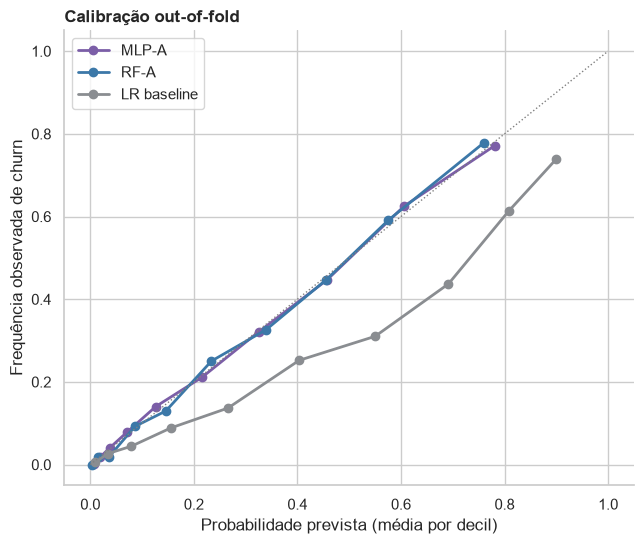

In [13]:
FINAL = {"MLP-A": make_mlp_a, "RF-A": make_rf_a, "LR baseline": make_baseline_lr}
oof = {n: cross_val_predict(f(), X_train, y_train, cv=CV5, method="predict_proba")[:, 1] for n, f in FINAL.items()}
oof_table = pd.DataFrame({n: score_all(y_train_arr, p) for n, p in oof.items()}).T
display(oof_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(6.6, 5.6))
for n, c in [("MLP-A", C_M), ("RF-A", C_A), ("LR baseline", C_BASE)]:
    q = pd.qcut(oof[n], 10, duplicates="drop")
    g = pd.DataFrame({"y": y_train_arr, "p": oof[n], "q": q}).groupby("q", observed=True).agg(y=("y", "mean"), p=("p", "mean"))
    ax.plot(g["p"], g["y"], marker="o", lw=2, color=c, label=n)
ax.plot([0, 1], [0, 1], ls=":", color="gray", lw=1)
ax.set_xlabel("Probabilidade prevista (média por decil)"); ax.set_ylabel("Frequência observada de churn")
ax.set_title("Calibração out-of-fold", loc="left", weight="bold"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura:** nas previsões out-of-fold, MLP-A apresenta ECE de 0,0078, menor que RF-A (0,0117) e muito menor que a regressão logística balanceada (0,1244). Isso indica boa concordância entre probabilidades médias e frequências observadas nessa avaliação OOF.

Essa conclusão não se transfere automaticamente ao teste: na seção 8.1, ECE do MLP-A é 0,0357, enquanto RF-A apresenta 0,0144. Portanto, a calibração do MLP-A parece boa em OOF, mas não é superior de forma consistente fora da amostra. ECE depende também da forma de binning; deve ser interpretado junto ao Brier e às curvas de calibração.


In [14]:
def thresholds_from_oof(p):
    pr, rc, th = precision_recall_curve(y_train_arr, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[int(np.nanargmax(f1[:-1]))], th[np.where(rc[:-1] >= RECALL_FLOOR)[0][-1]]

THR = {n: thresholds_from_oof(oof[n]) for n in FINAL}
for n, (t1, t2) in THR.items():
    print(f"{n:12s} threshold F1 máx = {t1:.3f} | threshold recall ≥ {RECALL_FLOOR:.0%} = {t2:.3f}")

MLP-A        threshold F1 máx = 0.312 | threshold recall ≥ 80% = 0.283
RF-A         threshold F1 máx = 0.336 | threshold recall ≥ 80% = 0.292
LR baseline  threshold F1 máx = 0.604 | threshold recall ≥ 80% = 0.464


### 8.1 Avaliação no teste (uso único)

In [15]:
final_models = {n: f().fit(X_train, y_train) for n, f in FINAL.items()}
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_test_arr), len(y_test_arr)) for _ in range(N_BOOT)]
boot = {n: np.array([[roc_auc_score(y_test_arr[i], proba_test[n][i]), average_precision_score(y_test_arr[i], proba_test[n][i]),
                      precision_at_recall(y_test_arr[i], proba_test[n][i])] for i in boot_idx]) for n in FINAL}

rows = []
for n in ["LR baseline", "RF-A", "MLP-A"]:
    s = score_all(y_test_arr, proba_test[n]); ci = lambda k: np.percentile(boot[n][:, k], [2.5, 97.5])
    rows.append({"modelo": n, "AUC": f"{s['AUC']:.4f} [{ci(0)[0]:.3f}-{ci(0)[1]:.3f}]", "AP": f"{s['AP']:.4f} [{ci(1)[0]:.3f}-{ci(1)[1]:.3f}]",
                 P80: f"{s[P80]:.3f} [{ci(2)[0]:.3f}-{ci(2)[1]:.3f}]", "Brier": f"{s['Brier']:.4f}", "ECE": f"{s['ECE']:.4f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

rows = []
for a, b in [("MLP-A", "LR baseline"), ("MLP-A", "RF-A"), ("RF-A", "LR baseline")]:
    r = {"comparação": f"{a} − {b}"}
    for k, m in enumerate(["AUC", "AP", P80]):
        d = boot[a][:, k] - boot[b][:, k]; lo, hi = np.percentile(d, [2.5, 97.5])
        r[f"Δ{m}"] = f"{d.mean():+.4f} [{lo:+.4f}; {hi:+.4f}]" + (" *" if (lo > 0 or hi < 0) else "")
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))
print("* = IC95 % (bootstrap pareado no teste) exclui zero.")

modelo,AUC,AP,P@R80,Brier,ECE
LR baseline,0.8364 [0.814-0.858],0.6248 [0.572-0.678],0.496 [0.449-0.558],0.1651,0.1266
RF-A,0.8560 [0.835-0.874],0.6714 [0.617-0.719],0.541 [0.481-0.583],0.1321,0.0144
MLP-A,0.8506 [0.828-0.871],0.6717 [0.622-0.715],0.503 [0.456-0.559],0.1355,0.0357


comparação,ΔAUC,ΔAP,ΔP@R80
MLP-A − LR baseline,+0.0141 [+0.0043; +0.0237] *,+0.0457 [+0.0134; +0.0770] *,+0.0042 [-0.0296; +0.0371]
MLP-A − RF-A,-0.0054 [-0.0135; +0.0020],-0.0002 [-0.0176; +0.0190],-0.0311 [-0.0585; -0.0008] *
RF-A − LR baseline,+0.0195 [+0.0072; +0.0310] *,+0.0459 [+0.0127; +0.0783] *,+0.0353 [-0.0019; +0.0723]


* = IC95 % (bootstrap pareado no teste) exclui zero.


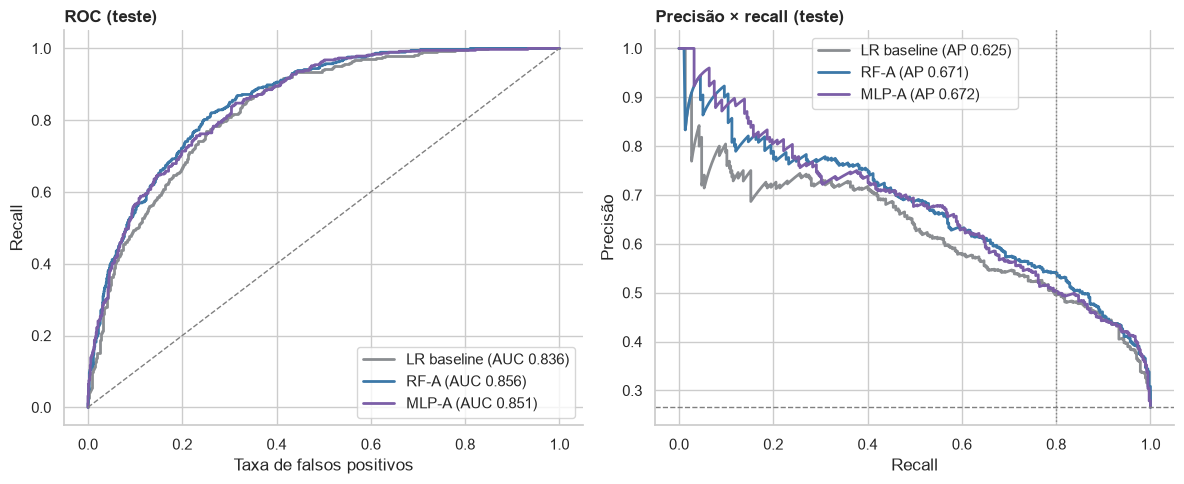

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for n, c in [("LR baseline", C_BASE), ("RF-A", C_A), ("MLP-A", C_M)]:
    fpr, tpr, _ = roc_curve(y_test_arr, proba_test[n]); axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC {roc_auc_score(y_test_arr, proba_test[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test_arr, proba_test[n]); axes[1].plot(rc, pr, color=c, lw=2, label=f"{n} (AP {average_precision_score(y_test_arr, proba_test[n]):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="gray", lw=1); axes[0].set_xlabel("Taxa de falsos positivos"); axes[0].set_ylabel("Recall"); axes[0].set_title("ROC (teste)", loc="left", weight="bold")
axes[1].axhline(y_test_arr.mean(), ls="--", color="gray", lw=1); axes[1].axvline(RECALL_FLOOR, ls=":", color="gray", lw=1)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precisão"); axes[1].set_title("Precisão × recall (teste)", loc="left", weight="bold")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

In [17]:
rows = []
for n in ["LR baseline", "RF-A", "MLP-A"]:
    for label, thr in [("threshold 0,5", 0.5), ("F1 máximo (OOF)", THR[n][0]), (f"recall ≥ {RECALL_FLOOR:.0%} (OOF)", THR[n][1])]:
        pred = proba_test[n] >= thr
        tp = int((pred & (y_test_arr == 1)).sum()); fp = int((pred & (y_test_arr == 0)).sum()); fn = int((~pred & (y_test_arr == 1)).sum())
        rows.append({"modelo": n, "ponto de operação": label, "threshold": thr, "TP": tp, "FP": fp, "FN": fn,
                     "precisão": tp / (tp + fp), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn)})
op_table = pd.DataFrame(rows)
display(op_table.style.format({"threshold": "{:.3f}", "precisão": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"}).hide(axis="index"))
n_pos_test = int(y_test_arr.sum()); tp80 = RECALL_FLOOR * n_pos_test
fp80 = {n: tp80 * (1 - precision_at_recall(y_test_arr, proba_test[n])) / precision_at_recall(y_test_arr, proba_test[n]) for n in FINAL}
print(f"Falsos positivos esperados para capturar {RECALL_FLOOR:.0%} dos churners no teste (≈ {tp80:.0f} de {n_pos_test}): " + " | ".join(f"{n}: {v:.0f}" for n, v in fp80.items()))
print(f"FP evitados pelo MLP-A sobre o baseline no mesmo recall: ≈ {fp80['LR baseline'] - fp80['MLP-A']:.0f} | sobre o RF-A: ≈ {fp80['RF-A'] - fp80['MLP-A']:.0f}")

modelo,ponto de operação,threshold,TP,FP,FN,precisão,recall,F1
LR baseline,"threshold 0,5",0.500,284,259,90,0.523,0.759,0.619
LR baseline,F1 máximo (OOF),0.604,251,208,123,0.547,0.671,0.603
LR baseline,recall ≥ 80% (OOF),0.464,294,288,80,0.505,0.786,0.615
RF-A,"threshold 0,5",0.500,203,102,171,0.666,0.543,0.598
RF-A,F1 máximo (OOF),0.336,282,225,92,0.556,0.754,0.640
RF-A,recall ≥ 80% (OOF),0.292,300,256,74,0.540,0.802,0.645
MLP-A,"threshold 0,5",0.500,228,138,146,0.623,0.610,0.616
MLP-A,F1 máximo (OOF),0.312,295,284,79,0.509,0.789,0.619
MLP-A,recall ≥ 80% (OOF),0.283,306,313,68,0.494,0.818,0.616


Falsos positivos esperados para capturar 80% dos churners no teste (≈ 299 de 374): MLP-A: 296 | RF-A: 254 | LR baseline: 304
FP evitados pelo MLP-A sobre o baseline no mesmo recall: ≈ 8 | sobre o RF-A: ≈ -42


**Leitura da avaliação final (teste reservado):**

- **MLP-A versus baseline logístico:** MLP-A apresenta AUC +0,0141 (IC95 % [+0,0043; +0,0237]) e AP +0,0457 (IC95 % [+0,0134; +0,0770]). Os intervalos pareados de bootstrap não incluem zero. A comparação é útil como referência histórica, mas não isola o algoritmo: o baseline utiliza geografia e 23 features, enquanto MLP-A utiliza 19 features sem geografia.
- **MLP-A versus RF-A:** AP é praticamente igual (Δ −0,0002; IC95 % [−0,0176; +0,0190]) e a diferença de AUC (−0,0054; IC95 % [−0,0135; +0,0020]) não é conclusiva. Já `P@R80` é menor para MLP-A (Δ −0,0311; IC95 % [−0,0585; −0,0008]) pelo bootstrap pareado. Essa métrica é ruidosa com 374 churners e deve ser interpretada com cautela, mas aponta para melhor precisão do RF-A nesse ponto de operação.
- **CV → teste:** AUC cai de 0,8642 para 0,8506 no MLP-A (−0,0136), de 0,8634 para 0,8560 no RF-A (−0,0074) e de 0,8481 para 0,8364 no baseline (−0,0117). A queda maior do MLP-A é compatível com algum otimismo de seleção entre candidatas, mas os intervalos se sobrepõem; não prova sobreajuste por si só.
- **Thresholds escolhidos via OOF:** no teste, o threshold de recall ≥ 80 % produz MLP-A com 306 TP, 313 FP, 68 FN, Precision 0,494, Recall 0,818 e F1 0,616. Para RF-A, são 300 TP, 256 FP, 74 FN, Precision 0,540, Recall 0,802 e F1 0,645. Portanto, RF-A captura proporção semelhante de churners com menos falsos positivos.
- **Não confundir dois pontos de operação:** a tabela de thresholds usa o valor definido no OOF e aplica esse valor ao teste. Já `P@R80` é calculado a partir da curva precision-recall do próprio teste para descrever a precisão alcançável ao redor de recall 80 %; não representa o mesmo threshold nem deve ser usado para ajustar o modelo.
- **Threshold 0,5:** no MLP-A, produz Recall 0,610 e F1 0,616; o ponto de operação depende do threshold e não deve ser presumido como 0,5.
- **Calibração no teste:** Brier/ECE do MLP-A são 0,1355/0,0357, contra 0,1321/0,0144 do RF-A. O RF-A apresenta probabilidades melhor calibradas nesta amostra de teste.

**Conclusão da seção:** MLP-A e RF-A empatam no ranking no teste dentro da incerteza observada, mas RF-A tem vantagem prática no ponto de operação de recall próximo a 80 % e na calibração do teste. Para este dataset e protocolo, RF-A permanece a referência preferida; MLP-A é uma alternativa competitiva, sem superioridade demonstrada.


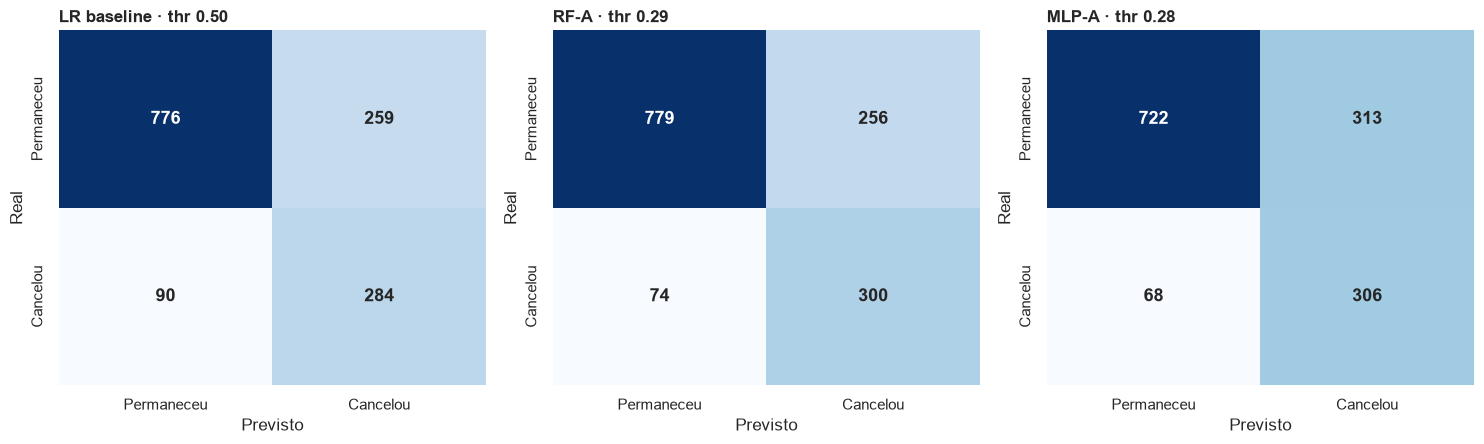

In [18]:
def lift_table(y_true, proba):
    d = pd.DataFrame({"y": y_true, "p": proba})
    d["decil"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    g = d.groupby("decil", observed=True).agg(clientes=("y", "size"), churners=("y", "sum"), churn=("y", "mean"))
    g["lift"] = g["churn"] / d["y"].mean(); g["recall acum."] = g["churners"].cumsum() / d["y"].sum()
    return g

lifts = pd.concat({n: lift_table(y_test_arr, proba_test[n])[["churn", "lift", "recall acum."]] for n in ["LR baseline", "RF-A", "MLP-A"]}, axis=1)
display(lifts.style.format("{:.3f}"))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, n in zip(axes, ["LR baseline", "RF-A", "MLP-A"]):
    thr = 0.5 if n == "LR baseline" else THR[n][1]
    cm = confusion_matrix(y_test_arr, (proba_test[n] >= thr).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 13, "weight": "bold"},
                xticklabels=["Permaneceu", "Cancelou"], yticklabels=["Permaneceu", "Cancelou"])
    ax.set_title(f"{n} · thr {thr:.2f}", loc="left", weight="bold"); ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

**Leitura do lift:** no primeiro decil de maior risco, a taxa observada de churn é 75,9 % para MLP-A (lift 2,86), 77,3 % para RF-A (lift 2,91) e 73,8 % para o baseline (lift 2,78). Os quatro primeiros decis acumulam 77,5 % dos churners no MLP-A, 80,7 % no RF-A e 77,8 % no baseline. Os quatro últimos decis concentram aproximadamente 5,1 %, 5,6 % e 6,7 % dos churners, respectivamente.

A leitura é de priorização: os três modelos concentram churners nas faixas de maior risco, com pequena vantagem do RF-A nos primeiros decis. O lift não informa, sozinho, se a campanha de retenção será eficaz ou rentável; isso depende de capacidade operacional, custo de contato e efeito causal da intervenção.


## 9. Interpretação do MLP-A

A interpretação é pós-hoc e descritiva. A importância por permutação mede quanto a métrica AP cai quando uma variável é embaralhada no conjunto avaliado; as análises “e se” alteram uma variável por vez e calculam a média das probabilidades previstas.

Essas análises ajudam a entender como o modelo utiliza os atributos, mas não estimam efeitos causais. A importância pode ser compartilhada entre variáveis correlacionadas; por isso, rankings individuais devem ser interpretados em conjunto com a estrutura dos dados.


c:\Users\danta\Desktop\projetos\pos\modelo-previsao-churn-telecom\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\danta\Desktop\projetos\pos\modelo-previsao-churn-telecom\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\danta\Desktop\projetos\pos\modelo-previsao-churn-telecom\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

Correlação de postos entre as previsões de MLP-A e RF-A no teste: 0.955 | sobreposição do 1º decil (Jaccard): 0.72 | correlação das importâncias: 0.76


,MLP-A,RF-A,média
Tenure Months,0.0779,0.0710,0.0745
Contract,0.0324,0.0845,0.0585
Total Charges,0.0694,0.0369,0.0532
Dependents,0.0437,0.0491,0.0464
Internet Service,0.0119,0.0364,0.0242
Monthly Charges,0.0263,0.0073,0.0168
Online Security,0.0110,0.0187,0.0148
Tech Support,0.0073,0.0146,0.0109
Paperless Billing,0.0068,-0.0008,0.0030
Online Backup,0.0034,0.0011,0.0023


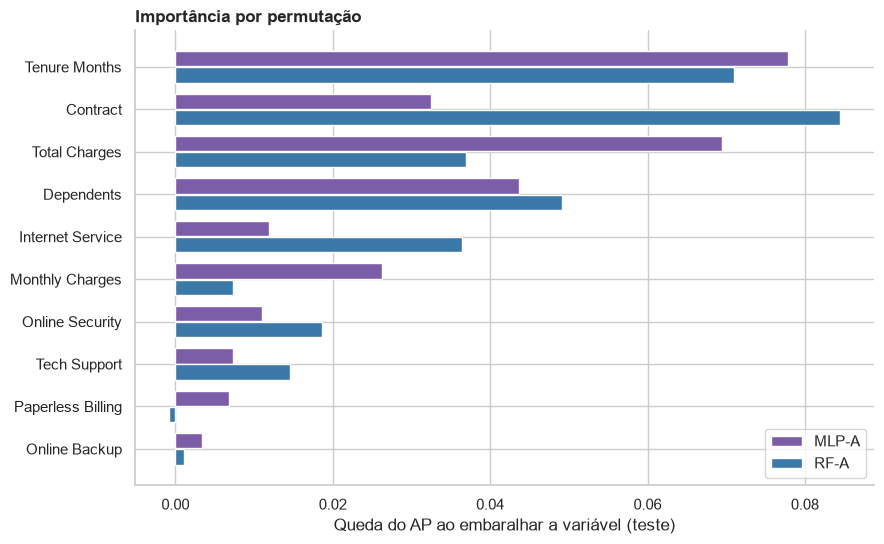

In [19]:
perm = {}
for n in ["MLP-A", "RF-A"]:
    r = permutation_importance(final_models[n], X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
    perm[n] = pd.Series(r.importances_mean, index=X_test.columns)
imp = pd.DataFrame(perm).loc[FEATURES]
imp["média"] = imp.mean(axis=1)
imp = imp.sort_values("média", ascending=False)
rho_imp = spearmanr(imp["MLP-A"], imp["RF-A"]).statistic
rho_pred = spearmanr(proba_test["MLP-A"], proba_test["RF-A"]).statistic
k10 = int(0.10 * len(y_test_arr))
ta, tb = set(np.argsort(-proba_test["MLP-A"])[:k10]), set(np.argsort(-proba_test["RF-A"])[:k10])
print(f"Correlação de postos entre as previsões de MLP-A e RF-A no teste: {rho_pred:.3f} | sobreposição do 1º decil (Jaccard): {len(ta & tb) / len(ta | tb):.2f} | correlação das importâncias: {rho_imp:.2f}")
display(imp.head(10).style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(9, 5.6))
top = imp.head(10).iloc[::-1]; ypos = np.arange(len(top))
ax.barh(ypos + 0.19, top["MLP-A"], height=0.36, color=C_M, label="MLP-A"); ax.barh(ypos - 0.19, top["RF-A"], height=0.36, color=C_A, label="RF-A")
ax.set_yticks(ypos); ax.set_yticklabels(top.index); ax.set_xlabel("Queda do AP ao embaralhar a variável (teste)")
ax.set_title("Importância por permutação", loc="left", weight="bold"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura:** MLP-A e RF-A produzem rankings de risco semelhantes no teste (correlação de postos 0,955; Jaccard de sobreposição do primeiro decil 0,72) e têm correlação de 0,76 entre as importâncias por permutação apresentadas.

Há diferenças na distribuição da importância: MLP-A atribui maior queda de AP a `Tenure Months` (0,078), `Total Charges` (0,069) e `Monthly Charges` (0,026); RF-A atribui maior importância a `Contract` (0,085), seguido de `Total Charges` (0,037). Isso descreve como cada modelo utiliza a informação sob seu próprio pré-processamento; não demonstra mecanismo causal nem que uma família de modelos “entenda” melhor determinada variável.


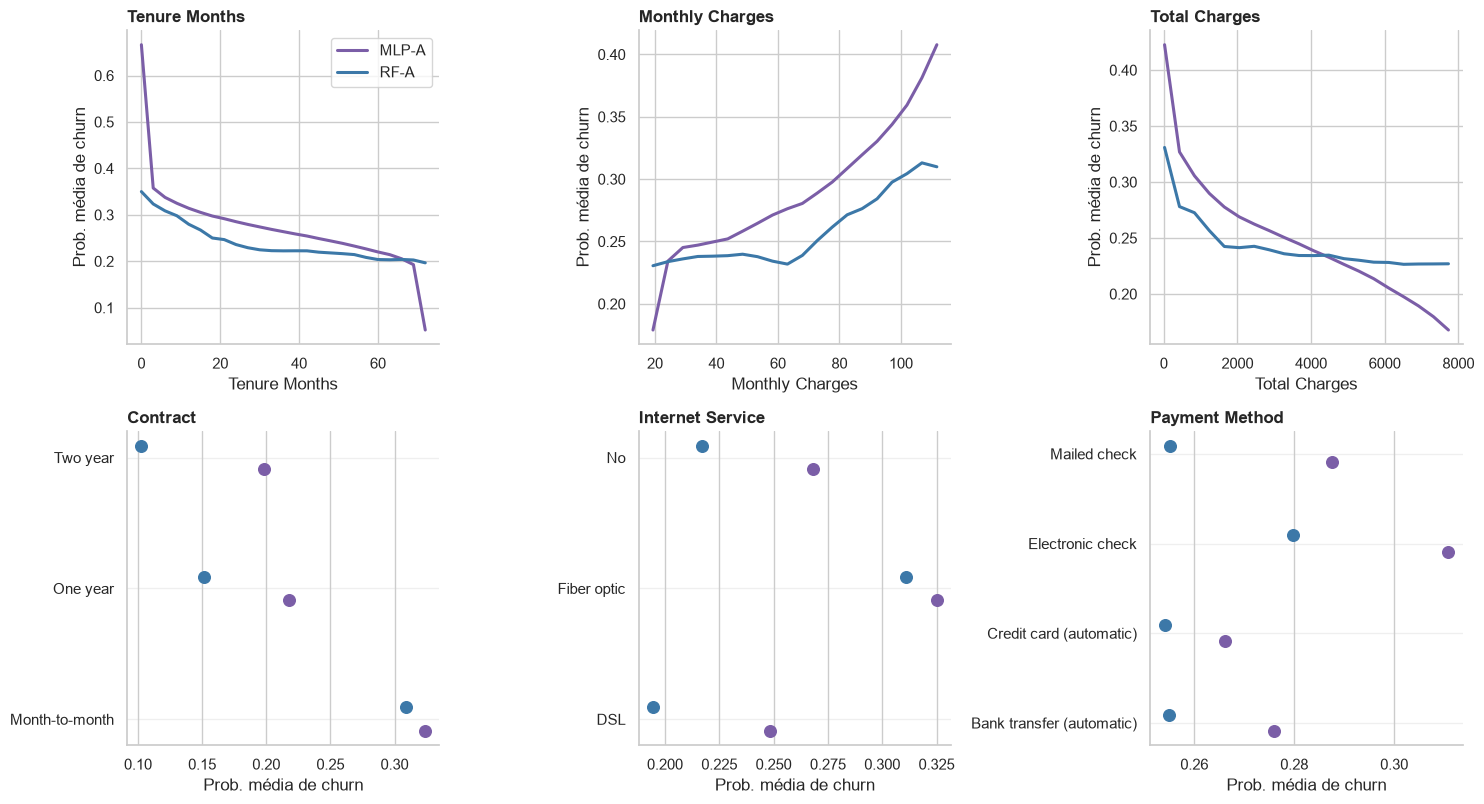

In [20]:
def what_if(model, col, values, ref=X_train):
    out = []
    for v in values:
        Xv = ref.copy(); Xv[col] = v
        out.append(model.predict_proba(Xv)[:, 1].mean())
    return np.array(out)

num_grids = {"Tenure Months": np.arange(0, 73, 3),
             "Monthly Charges": np.linspace(*np.percentile(X_train["Monthly Charges"], [2, 98]), 20),
             "Total Charges": np.linspace(*np.percentile(X_train["Total Charges"].dropna(), [2, 98]), 20)}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, (col, grid) in zip(axes[0], num_grids.items()):
    for n, c in [("MLP-A", C_M), ("RF-A", C_A)]:
        ax.plot(grid, what_if(final_models[n], col, grid), color=c, lw=2.2, label=n)
    ax.set_xlabel(col); ax.set_ylabel("Prob. média de churn"); ax.set_title(col, loc="left", weight="bold")
axes[0][0].legend()
for ax, col in zip(axes[1], ["Contract", "Internet Service", "Payment Method"]):
    levels = sorted(X_train[col].unique())
    for k, (n, c) in enumerate([("MLP-A", C_M), ("RF-A", C_A)]):
        ax.scatter([what_if(final_models[n], col, [lv])[0] for lv in levels], np.arange(len(levels)) + (k - 0.5) * 0.18, color=c, s=70, label=n, zorder=3)
    ax.set_yticks(range(len(levels))); ax.set_yticklabels(levels); ax.set_xlabel("Prob. média de churn"); ax.set_title(col, loc="left", weight="bold"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Cuidados de leitura:** (1) `Monthly Charges` é quase determinado pela combinação de serviços na amostra (R² = 0,9988 no treino), portanto o efeito isolado de preço e de serviços é difícil de separar; (2) o “e se” altera uma variável por vez e pode criar combinações de atributos que não existem na população; (3) resultados são associações produzidas pelo modelo, não efeitos causais. Para variáveis correlacionadas, a importância pode ser distribuída entre substitutos.


### 9.1 Desempenho por segmento (out-of-fold, MLP-A)

A EDA indica taxas de churn diferentes entre segmentos. A tabela abaixo avalia especificamente o MLP-A usando probabilidades out-of-fold do treino. Ela permite verificar se o ranking global se mantém dentro dos principais grupos; não é uma comparação segmentada entre algoritmos.


In [21]:
seg = X_train[FEATURES].copy()
seg["y"] = y_train_arr; seg["p"] = oof["MLP-A"]
seg["Faixa de tenure"] = pd.cut(seg["Tenure Months"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
rows = []
for col in ["Contract", "Faixa de tenure", "Internet Service", "Payment Method"]:
    for lv, g in seg.groupby(col, observed=True):
        if g["y"].nunique() < 2:
            continue
        rows.append({"variável": col, "grupo": str(lv), "n": len(g), "churn real": g["y"].mean(), "prev. média": g["p"].mean(),
                     "AUC": roc_auc_score(g["y"], g["p"]), "AP": average_precision_score(g["y"], g["p"])})
seg_table = pd.DataFrame(rows)
display(seg_table.style.format({c: "{:.3f}" for c in ["churn real", "prev. média", "AUC", "AP"]}).hide(axis="index"))

variável,grupo,n,churn real,prev. média,AUC,AP
Contract,Month-to-month,3102,0.427,0.423,0.781,0.721
Contract,One year,1173,0.111,0.112,0.787,0.279
Contract,Two year,1359,0.029,0.033,0.827,0.131
Faixa de tenure,0-6,1170,0.522,0.517,0.786,0.792
Faixa de tenure,7-12,567,0.372,0.369,0.826,0.741
Faixa de tenure,13-24,818,0.286,0.289,0.825,0.586
Faixa de tenure,25-48,1290,0.202,0.209,0.833,0.539
Faixa de tenure,49-72,1789,0.099,0.095,0.856,0.411
Internet Service,DSL,1937,0.187,0.188,0.820,0.517
Internet Service,Fiber optic,2483,0.421,0.416,0.822,0.750


**Leitura por segmento:**

- **Alinhamento das médias por grupo:** a probabilidade média prevista fica próxima da taxa observada em cada grupo (diferença absoluta de até aproximadamente 0,007 na tabela). Isso é um sinal de alinhamento agregado por segmento, não uma demonstração completa de calibração individual.
- **Discriminação menor em segmentos de alta prevalência:** contrato mensal (churn 42,7 %, AUC 0,781), tenure de 0–6 meses (52,2 %, AUC 0,786) e pagamento por cheque eletrônico (45,7 %, AUC 0,798). O contrato de um ano também tem AUC 0,787, embora a prevalência seja baixa (11,1 %).
- **Interpretação:** a separação dentro de alguns segmentos é mais difícil do que a separação agregada (AUC global OOF 0,864). Parte da discriminação global pode vir de diferenças de prevalência entre segmentos, mas esta tabela não decompõe formalmente o AUC global. Não se conclui que os clientes sejam indistinguíveis nem que o limite seja independente do algoritmo.

A análise é apenas do MLP-A; a tabela não permite afirmar que o mesmo padrão segmentado foi medido para RF-A.


## 10. Evidências sobre os limites observados com as variáveis atuais

As subseções seguintes investigam explicações alternativas para o desempenho observado do MLP-A: capacidade e regularização, variação entre sementes, volume de dados, contribuição incremental das variáveis, comparação entre famílias de modelos e hipóteses sobre preço e renovação.

O termo “limite” é utilizado no sentido de uma faixa observada nos experimentos deste notebook. As análises não demonstram um teto teórico, nem provam que nenhum algoritmo ou dado adicional possa superar os resultados apresentados.


### 10.1 Capacidade e regularização: curvas de validação (alpha, largura, épocas)

AUC de treino (tracejado) e de validação (linha contínua), variando **um** hiperparâmetro do MLP-A por vez. Como as demais escolhas permanecem fixas, as curvas mostram sensibilidade local em torno do MLP-A, não uma busca exaustiva de todas as interações possíveis.


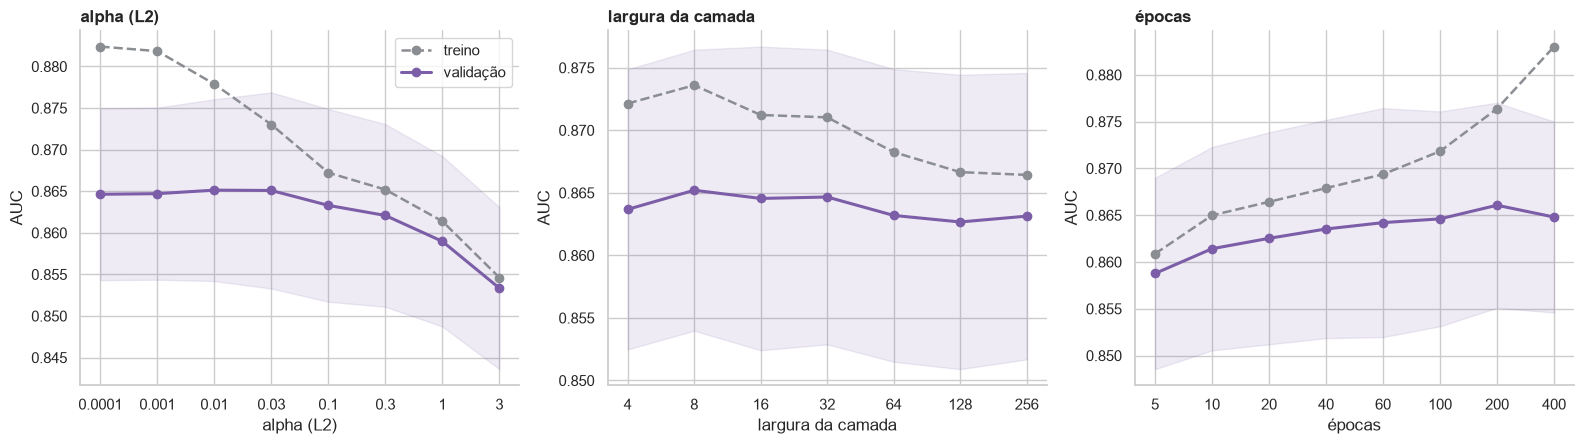

alpha (L2)         melhor AUC de validação 0.8651 em 0.01 | pior 0.8533 | faixa a ≤ 0,002 do máximo: ['0.0001', '0.001', '0.01', '0.03', '0.1']
largura da camada  melhor AUC de validação 0.8652 em (8,) | pior 0.8627 | faixa a ≤ 0,002 do máximo: ['(4,)', '(8,)', '(16,)', '(32,)']
épocas             melhor AUC de validação 0.8661 em 200.0 | pior 0.8588 | faixa a ≤ 0,002 do máximo: ['60', '100', '200', '400']


alpha,AUC treino,AUC validação,dp,AP validação
0.000100,0.8824,0.8646,0.0103,0.6902
0.001000,0.8818,0.8647,0.0103,0.6909
0.010000,0.8779,0.8651,0.0109,0.6929
0.030000,0.8730,0.8651,0.0118,0.6948
0.100000,0.8672,0.8633,0.0116,0.6930
0.300000,0.8652,0.8621,0.0110,0.6899
1.000000,0.8614,0.8590,0.0102,0.6815
3.000000,0.8546,0.8533,0.0097,0.6691


In [22]:
def val_curve(name, values, **fixed):
    rows = []
    for v in values:
        tr, va, vap = [], [], []
        for a, b in CV5.split(X_train, y_train):
            m = make_mlp(**{**PARAMS_A, **fixed, name: v}).fit(X_train.iloc[a], y_train.iloc[a])
            tr.append(roc_auc_score(y_train_arr[a], m.predict_proba(X_train.iloc[a])[:, 1]))
            pb = m.predict_proba(X_train.iloc[b])[:, 1]
            va.append(roc_auc_score(y_train_arr[b], pb)); vap.append(average_precision_score(y_train_arr[b], pb))
        rows.append({name: v, "AUC treino": np.mean(tr), "AUC validação": np.mean(va), "dp": np.std(va), "AP validação": np.mean(vap)})
    return pd.DataFrame(rows)

vc = {
    "alpha (L2)": val_curve("alpha", [1e-4, 1e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0, 3.0]),
    "largura da camada": val_curve("hidden", [(4,), (8,), (16,), (32,), (64,), (128,), (256,)]),
    "épocas": val_curve("max_iter", [5, 10, 20, 40, 60, 100, 200, 400], patience=10000, tol=0.0),
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (title, t) in zip(axes, vc.items()):
    key = t.columns[0]; xs = np.arange(len(t)); labels = [str(v[0]) if isinstance(v, tuple) else (f"{v:g}") for v in t[key]]
    ax.plot(xs, t["AUC treino"], ls="--", marker="o", color=C_BASE, lw=1.8, label="treino")
    ax.plot(xs, t["AUC validação"], marker="o", color=C_M, lw=2.2, label="validação")
    ax.fill_between(xs, t["AUC validação"] - t["dp"], t["AUC validação"] + t["dp"], color=C_M, alpha=0.12)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_xlabel(title); ax.set_ylabel("AUC"); ax.set_title(title, loc="left", weight="bold")
axes[0].legend(); plt.tight_layout(); plt.show()
for title, t in vc.items():
    best = t.loc[t["AUC validação"].idxmax()]
    print(f"{title:18s} melhor AUC de validação {best['AUC validação']:.4f} em {best.iloc[0]} | pior {t['AUC validação'].min():.4f} | faixa a ≤ 0,002 do máximo: {[str(v) for v in t[t['AUC validação'] >= best['AUC validação'] - 0.002].iloc[:, 0]]}")
display(vc["alpha (L2)"].style.format({c: "{:.4f}" for c in ["AUC treino", "AUC validação", "dp", "AP validação"]}).hide(axis="index"))

**Leitura:** dentro do grid avaliado, o AUC de validação varia pouco em uma faixa ampla de regularização e arquitetura, mas não é completamente plano:

- `alpha` entre 1e-4 e 0,1 permanece até aproximadamente 0,002 do melhor AUC (0,8651 em 0,01). `alpha` 1,0 e 3,0 pioram mais (0,8590 e 0,8533).
- **Largura:** de 4 a 32 neurônios fica até 0,002 do melhor (0,8652 com 8 neurônios); 256 neurônios alcançam 0,8627.
- **Épocas:** 60 a 400 ficam até 0,002 do melhor (0,8661 em 200); cinco épocas produzem 0,8588, compatível com subajuste.

Com `alpha=1e-4`, o AUC de treino é 0,8824 e o de validação 0,8646, diferença de aproximadamente 0,018. Isso sugere alguma diferença entre ajuste e generalização, mas não um sobreajuste extremo. A conclusão adequada é que, **entre as variações testadas**, aumentar muito a capacidade não trouxe ganho claro; não se pode afirmar que toda a capacidade do MLP foi esgotada ou que o limite de desempenho é teórico.


### 10.2 Estabilidade: variação por semente de inicialização

O MLP depende de inicialização aleatória. Para isolar esse componente, o notebook mantém o mesmo fold de treino/validação e ajusta 20 modelos com sementes diferentes. A análise mede a variação de inicialização nesse fold específico; não substitui a variação entre amostras ou entre partições.


In [23]:
a0, b0 = next(iter(CV5.split(X_train, y_train)))
seed_rows = [score_all(y_train_arr[b0], make_mlp_a(seed=s).fit(X_train.iloc[a0], y_train.iloc[a0]).predict_proba(X_train.iloc[b0])[:, 1]) for s in range(20)]
seed_df = pd.DataFrame(seed_rows)
print(f"20 sementes, mesmo fold: AUC {seed_df['AUC'].mean():.4f} ± {seed_df['AUC'].std():.4f} (amplitude {seed_df['AUC'].max() - seed_df['AUC'].min():.4f}) | "
      f"AP {seed_df['AP'].mean():.4f} ± {seed_df['AP'].std():.4f} (amplitude {seed_df['AP'].max() - seed_df['AP'].min():.4f}) | {P80} {seed_df[P80].mean():.3f} ± {seed_df[P80].std():.3f}")

20 sementes, mesmo fold: AUC 0.8615 ± 0.0005 (amplitude 0.0021) | AP 0.6738 ± 0.0009 (amplitude 0.0042) | P@R80 0.579 ± 0.004


**Leitura:** no fold avaliado, a variação entre 20 sementes é pequena: AUC 0,8615 ± 0,0005 (amplitude 0,0021) e AP 0,6738 ± 0,0009 (amplitude 0,0042). A variação de AUC é menor que o desvio observado entre folds (cerca de 0,009 nas tabelas de CV).

Isso indica que a inicialização não é a principal fonte de variação nesse fold. É compatível com os resultados de média de sementes e bagging, que não mostraram ganho relevante de AP. A conclusão deve permanecer restrita à configuração e à partição analisadas.


### 10.3 Volume de dados: curva de aprendizado (MLP-A e RF-A)

A curva mede AUC e AP de validação quando o tamanho do subconjunto de treinamento aumenta de 25 % para 100 % do conjunto disponível em cada fold. Os pontos representam a média entre folds, com dispersão indicada no gráfico.


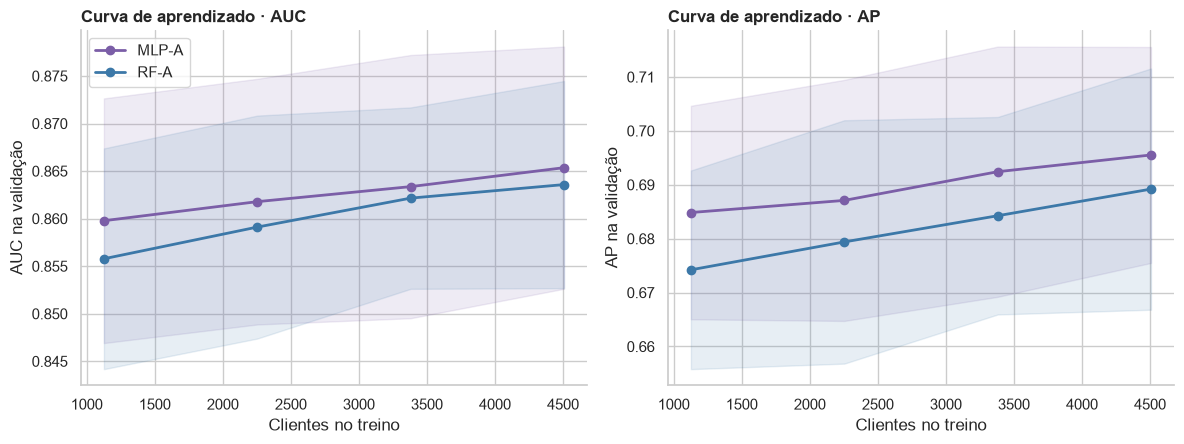

MLP-A: AUC com 50 % dos dados 0.8618 | 75 % 0.8634 | 100 % 0.8654 | ganho de 75 % → 100 %: +0.0020
RF-A: AUC com 50 % dos dados 0.8591 | 75 % 0.8622 | 100 % 0.8636 | ganho de 75 % → 100 %: +0.0014


In [24]:
def learning_curve_cv(factory, fractions=(0.25, 0.5, 0.75, 1.0), seed=0):
    rng_l = np.random.default_rng(seed); rows = []
    for fold, (a, b) in enumerate(CV5.split(X_train, y_train)):
        for f in fractions:
            idx = rng_l.choice(a, int(len(a) * f), replace=False)
            p = factory().fit(X_train.iloc[idx], y_train.iloc[idx]).predict_proba(X_train.iloc[b])[:, 1]
            rows.append({"fração": f, "n": len(idx), "fold": fold, "AUC": roc_auc_score(y_train_arr[b], p), "AP": average_precision_score(y_train_arr[b], p)})
    return pd.DataFrame(rows)

lc = {"MLP-A": learning_curve_cv(make_mlp_a), "RF-A": learning_curve_cv(make_rf_a)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, metric in zip(axes, ["AUC", "AP"]):
    for n, c in [("MLP-A", C_M), ("RF-A", C_A)]:
        g = lc[n].groupby("fração").agg(n=("n", "mean"), m=(metric, "mean"), sd=(metric, "std"))
        ax.plot(g["n"], g["m"], marker="o", color=c, lw=2, label=n); ax.fill_between(g["n"], g["m"] - g["sd"], g["m"] + g["sd"], color=c, alpha=0.12)
    ax.set_xlabel("Clientes no treino"); ax.set_ylabel(f"{metric} na validação"); ax.set_title(f"Curva de aprendizado · {metric}", loc="left", weight="bold")
axes[0].legend(); plt.tight_layout(); plt.show()
lc_table = pd.concat({n: lc[n].groupby("fração").agg(clientes=("n", "mean"), AUC=("AUC", "mean"), AP=("AP", "mean")) for n in lc}, axis=1)
display(lc_table.style.format({c: "{:.0f}" if c[1] == "clientes" else "{:.4f}" for c in lc_table.columns}))
for n in lc:
    g = lc[n].groupby("fração")["AUC"].mean()
    print(f"{n}: AUC com 50 % dos dados {g[0.5]:.4f} | 75 % {g[0.75]:.4f} | 100 % {g[1.0]:.4f} | ganho de 75 % → 100 %: {g[1.0] - g[0.75]:+.4f}")

**Leitura:** ambos os modelos melhoram à medida que recebem mais dados no intervalo observado. Para MLP-A, o AUC passa de 0,8598 (25 %) para 0,8654 (100 %); para RF-A, de 0,8558 para 0,8636. Entre 75 % e 100 %, o ganho de AUC é +0,0020 para MLP-A e +0,0014 para RF-A.

O ganho marginal no trecho final é pequeno, mas a curva ainda está subindo. Portanto, os resultados não demonstram que mais dados seriam inúteis, nem permitem extrapolar quantitativamente o ganho para uma base duas vezes maior. A conclusão prudente é que mais dados podem ajudar, mas a magnitude fora do intervalo observado é desconhecida.


### 10.4 Variáveis: curva de acréscimo (MLP-A)

As variáveis são ordenadas por informação mútua com o target calculada no conjunto completo de treino e adicionadas uma a uma ao MLP-A. **Atenção metodológica:** como a ordenação é calculada antes da validação cruzada, os rótulos dos folds de validação participam da seleção da ordem das variáveis. Assim, os valores de AUC desta curva têm viés otimista e devem ser tratados como diagnóstico exploratório, não como estimativa imparcial do desempenho de subconjuntos.

Uma avaliação sem esse vazamento exigiria recalcular a informação mútua exclusivamente dentro do treino de cada fold (por exemplo, em uma seleção aninhada) e avaliar os subconjuntos nos folds correspondentes.


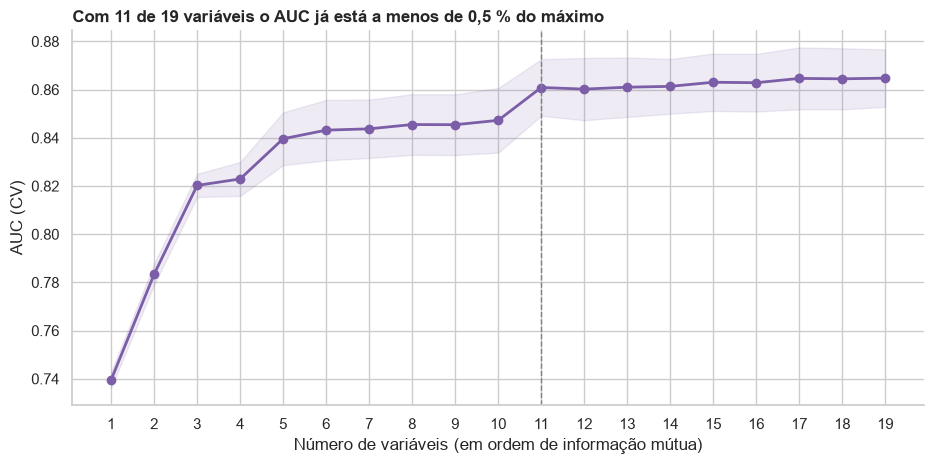

k,variável adicionada,AUC (CV),dp
1,Contract,0.7395,0.0032
2,Tenure Months,0.7834,0.0044
3,Online Security,0.8202,0.0048
4,Tech Support,0.8229,0.0070
5,Internet Service,0.8396,0.0109
6,Monthly Charges,0.8432,0.0125
7,Online Backup,0.8437,0.0121
8,Payment Method,0.8455,0.0126
9,Device Protection,0.8454,0.0126
10,Total Charges,0.8472,0.0134


AUC com 1 variável: 0.7395 | com 2: 0.7834 | com 5: 0.8396 | com 11: 0.8609 | com todas (19): 0.8647
As 8 últimas variáveis somam +0.0039 de AUC (desvio entre folds ≈ 0.012).


In [25]:
Xo = X_train[FEATURES].copy()
for c in CAT:
    Xo[c] = Xo[c].astype("category").cat.codes
Xo["Total Charges"] = Xo["Total Charges"].fillna(0)
mi = pd.Series(mutual_info_classif(Xo, y_train, discrete_features=[c in CAT for c in FEATURES], random_state=SEED), index=FEATURES)
order = mi.sort_values(ascending=False).index.tolist()
rows = []
for k in range(1, len(order) + 1):
    cols = order[:k]; aucs = []
    for a, b in CV5.split(X_train, y_train):
        m = make_mlp_a(num=[c for c in cols if c in NUM], cat=[c for c in cols if c in CAT]).fit(X_train.iloc[a], y_train.iloc[a])
        aucs.append(roc_auc_score(y_train_arr[b], m.predict_proba(X_train.iloc[b])[:, 1]))
    rows.append({"k": k, "variável adicionada": order[k - 1], "AUC (CV)": np.mean(aucs), "dp": np.std(aucs)})
accrual = pd.DataFrame(rows)
full_auc = accrual["AUC (CV)"].iloc[-1]
k_plateau = int(accrual.loc[accrual["AUC (CV)"] >= 0.995 * full_auc, "k"].iloc[0])
auc_k = accrual.set_index("k")["AUC (CV)"]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(accrual["k"], accrual["AUC (CV)"], marker="o", color=C_M, lw=2)
ax.fill_between(accrual["k"], accrual["AUC (CV)"] - accrual["dp"], accrual["AUC (CV)"] + accrual["dp"], color=C_M, alpha=0.12)
ax.axvline(k_plateau, color="gray", ls="--", lw=1); ax.set_xticks(accrual["k"])
ax.set_xlabel("Número de variáveis (em ordem de informação mútua)"); ax.set_ylabel("AUC (CV)")
ax.set_title(f"Com {k_plateau} de {len(order)} variáveis o AUC já está a menos de 0,5 % do máximo", loc="left", weight="bold")
plt.tight_layout(); plt.show()
display(accrual.style.format({"AUC (CV)": "{:.4f}", "dp": "{:.4f}"}).hide(axis="index"))
print(f"AUC com 1 variável: {auc_k[1]:.4f} | com 2: {auc_k[2]:.4f} | com 5: {auc_k[5]:.4f} | com {k_plateau}: {auc_k[k_plateau]:.4f} | com todas ({len(order)}): {full_auc:.4f}")
print(f"As {len(order) - k_plateau} últimas variáveis somam {full_auc - auc_k[k_plateau]:+.4f} de AUC (desvio entre folds ≈ {accrual['dp'].iloc[-1]:.3f}).")

**Leitura:** a curva exploratória sugere concentração de sinal nas primeiras variáveis da ordenação por informação mútua: `Contract` isoladamente alcança AUC 0,7395; com `Tenure Months`, 0,7834; com cinco variáveis, 0,8396; com 11, 0,8609; e com as 19, 0,8647. As oito últimas acrescentam +0,0039 de AUC na avaliação apresentada, enquanto o desvio entre folds é aproximadamente 0,012.

Como a informação mútua foi calculada uma única vez com todo o conjunto de treino antes da CV, a curva pode superestimar o desempenho dos subconjuntos. A leitura defensável é que as variáveis iniciais parecem concentrar boa parte do sinal neste diagnóstico; não se deve concluir que as oito restantes sejam inúteis ou que o conjunto de 11 seja comprovadamente ótimo.


### 10.5 Outro algoritmo veria mais? Comparação de famílias e ensemble

Comparação de ExtraTrees e regressão logística com splines contra MLP-A e RF-A nos mesmos 10 folds utilizados para técnicas/ablações (CV 5 × 2). A regressão logística baseline do usuário também aparece como referência, mas utiliza geografia e conjunto de features diferente; ela não constitui comparação controlada de algoritmo.


In [26]:
def make_et():
    pre = ColumnTransformer([("num", SimpleImputer(strategy="constant", fill_value=0.0), NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("pre", pre), ("clf", ExtraTreesClassifier(n_estimators=400, criterion="entropy", min_samples_leaf=8, max_features=0.5, random_state=SEED, n_jobs=-1))])



def make_lr_spline(C=0.1, n_knots=6):
    num_t = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                      ("spl", SplineTransformer(n_knots=n_knots, degree=3, include_bias=False)), ("sc", StandardScaler())])
    pre = ColumnTransformer([("n", num_t, NUM), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=5000))])

fam_new = run_cv({"ExtraTrees": make_et, "LR com splines": make_lr_spline}, CV_H)
fam_old = cand_folds[(cand_folds["modelo"].isin([NAME_A, "RF-A (EXP-07)", "LR baseline (usuário, com geo)"])) & (cand_folds["fold"] < 10)].copy()
fam_old["modelo"] = fam_old["modelo"].replace({NAME_A: "MLP-A", "RF-A (EXP-07)": "RF-A", "LR baseline (usuário, com geo)": "LR baseline"})
fam = pd.concat([fam_new, fam_old], ignore_index=True)
display(fam.groupby("modelo")[["AUC", "AP", P80]].mean().sort_values("AP", ascending=False).style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}"}))
rows = []
for other in ["RF-A", "ExtraTrees", "LR com splines"]:
    r = {"A − B": f"{other} − MLP-A"}
    for m in ["AUC", "AP", P80]:
        d, se, _ = paired(fam, other, "MLP-A", m); r[f"Δ{m} (EP)"] = f"{d:+.4f} ({se:.4f})"
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))

,AUC,AP,P@R80
modelo,,,
MLP-A,0.8644,0.6941,0.552
LR com splines,0.8622,0.6898,0.547
RF-A,0.8633,0.6894,0.546
ExtraTrees,0.8531,0.6607,0.528
LR baseline,0.8476,0.6534,0.521


A − B,ΔAUC (EP),ΔAP (EP),ΔP@R80 (EP)
RF-A − MLP-A,-0.0011 (0.0011),-0.0046 (0.0019),-0.0057 (0.0047)
ExtraTrees − MLP-A,-0.0112 (0.0016),-0.0334 (0.0044),-0.0239 (0.0038)
LR com splines − MLP-A,-0.0022 (0.0008),-0.0043 (0.0016),-0.0044 (0.0045)


**Leitura:** em CV 5 × 2, MLP-A apresenta as maiores médias (AUC 0,8644; AP 0,6941). RF-A fica próximo (AUC 0,8633; AP 0,6894), assim como a regressão logística com splines (0,8622; 0,6898). As diferenças pareadas são pequenas em termos absolutos e devem ser vistas como evidência exploratória, considerando apenas 10 folds repetidos. ExtraTrees fica abaixo (AUC 0,8531; AP 0,6607).

No teste reservado, a vantagem nominal do MLP-A sobre RF-A não se confirmou: AP praticamente empatado e AUC ligeiramente menor no MLP-A. Portanto, esta CV não sustenta a escolha do MLP como modelo principal. A regressão com splines é uma referência linear útil, enquanto a regressão logística baseline com geografia não é diretamente comparável por utilizar outro conjunto de atributos.


In [27]:
def rank_avg(ps):
    return np.mean([rankdata(p) / len(p) for p in ps], axis=0)

oof["LR com splines"] = cross_val_predict(make_lr_spline(), X_train, y_train, cv=CV5, method="predict_proba")[:, 1]
blends = {"MLP-A (isolado)": oof["MLP-A"], "RF-A (isolado)": oof["RF-A"],
          "LR com splines (isolado)": oof["LR com splines"],
          "MLP-A + RF-A": rank_avg([oof["MLP-A"], oof["RF-A"]])}
ens_table = pd.DataFrame({n: {k: v for k, v in score_all(y_train_arr, p).items() if k in ("AUC", "AP", P80)} for n, p in blends.items()}).T
display(ens_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}"}))
fp100 = lambda p: 100 * (1 - p) / p
best_iso = ens_table.loc[[n for n in ens_table.index if "isolado" in n], "AUC"].idxmax()
e2 = ens_table.loc["MLP-A + RF-A"]
print(f"Ensemble MLP-A + RF-A contra o MLP-A: ΔAUC = {e2['AUC'] - ens_table.loc['MLP-A (isolado)', 'AUC']:+.4f} | contra o melhor isolado ({best_iso}): ΔAUC = {e2['AUC'] - ens_table.loc[best_iso, 'AUC']:+.4f}")
print(f"Precisão@recall 80 %: MLP-A {ens_table.loc['MLP-A (isolado)', P80]:.3f} -> ensemble {e2[P80]:.3f} "
      f"({fp100(ens_table.loc['MLP-A (isolado)', P80]):.0f} -> {fp100(e2[P80]):.0f} FP por 100 churners captados)")

,AUC,AP,P@R80
MLP-A (isolado),0.8635,0.6884,0.551
RF-A (isolado),0.8625,0.6839,0.539
LR com splines (isolado),0.8617,0.6881,0.546
MLP-A + RF-A,0.8658,0.6909,0.551


Ensemble MLP-A + RF-A contra o MLP-A: ΔAUC = +0.0023 | contra o melhor isolado (MLP-A (isolado)): ΔAUC = +0.0023
Precisão@recall 80 %: MLP-A 0.551 -> ensemble 0.551 (81 -> 81 FP por 100 churners captados)


**Leitura:** a média de ranking MLP-A + RF-A aumenta AUC de 0,8635 para 0,8658 (+0,0023) e AP de 0,6884 para 0,6909 (+0,0025) em relação ao MLP-A isolado nas previsões OOF desta seção. `P@R80` permanece em 0,551.

O ganho de ranking é pequeno e não se traduz em melhora observada de precisão no recall-alvo. Além disso, o ensemble é avaliado nessas mesmas previsões OOF usadas para formar a combinação; sua vantagem deve ser confirmada em um procedimento de validação independente antes de ser considerada melhoria operacional. Por enquanto, é uma alternativa experimental.


### 10.6 Estrutura adicional: preço relativo e ciclo de renovação

Duas hipóteses de engenharia de features são testadas: (a) se o preço mensal contém informação residual depois de considerar os serviços contratados; (b) se o churn em contratos de um ano se concentra em determinados meses do ciclo de 12 meses.


In [28]:
services = ["Phone Service", "Multiple Lines", "Internet Service", "Online Security", "Online Backup",
            "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies"]
S = pd.get_dummies(X_train[services])
price_model = LinearRegression().fit(S, X_train["Monthly Charges"])
resid = X_train["Monthly Charges"] - price_model.predict(S)
print(f"(a) R² do preço mensal explicado só pelos serviços contratados: {price_model.score(S, X_train['Monthly Charges']):.4f} | desvio do resíduo: R$ {resid.std():.2f}")
q = pd.qcut(resid, 5)
display(pd.DataFrame({"churn": y_train.groupby(q, observed=True).mean(), "n": y_train.groupby(q, observed=True).size()})
        .rename_axis("quintil do resíduo de preço").style.format({"churn": "{:.3f}"}))
one_year = X_train["Contract"] == "One year"
cycle = pd.crosstab(X_train.loc[one_year, "Tenure Months"] % 12, y_train[one_year])
chi2, p_cycle, _, _ = chi2_contingency(cycle)
rate = y_train[one_year].groupby(X_train.loc[one_year, "Tenure Months"] % 12).mean()
print(f"(b) Contrato de 1 ano: churn por mês do ciclo (tenure mod 12) varia de {rate.min():.3f} a {rate.max():.3f}; "
      f"χ² de homogeneidade p = {p_cycle:.2f}  ->  {'sem evidência de ciclo' if p_cycle > 0.05 else 'há evidência de ciclo'}")

(a) R² do preço mensal explicado só pelos serviços contratados: 0.9988 | desvio do resíduo: R$ 1.03


,churn,n
quintil do resíduo de preço,,
"(-4.243, -0.764]",0.289,1136
"(-0.764, -0.231]",0.271,1118
"(-0.231, 0.214]",0.250,1126
"(0.214, 0.771]",0.249,1127
"(0.771, 4.808]",0.267,1127


(b) Contrato de 1 ano: churn por mês do ciclo (tenure mod 12) varia de 0.053 a 0.152; χ² de homogeneidade p = 0.18  ->  sem evidência de ciclo


**Leitura:** nas análises realizadas no conjunto de treino, não há evidência clara a favor das duas hipóteses testadas:

- Os serviços contratados explicam quase toda a variação de `Monthly Charges` (R² = 0,9988; desvio-padrão do resíduo ≈ R$ 1,03). O churn por quintil do resíduo não é monotônico (0,289 → 0,271 → 0,250 → 0,249 → 0,267), portanto não aparece um sinal simples de desconto/sobrepreço nessa representação.
- Para contratos de um ano, o teste de homogeneidade dos meses do ciclo resulta em p = 0,18. Não há evidência estatística, nesta amostra e nesta análise, de concentração do churn em um mês específico do ciclo.

A ausência de evidência nesses testes não prova inexistência de efeitos mais complexos ou de variáveis temporais que não estão disponíveis no dataset.


### 10.7 `Churn Score` como diagnóstico: variável excluída do modelo

Esta variável é examinada somente para diagnóstico e **não é utilizada como feature**. Sua origem, momento de cálculo e relação com o processo de cancelamento não estão documentados neste experimento; por isso, não é possível assegurar que estaria disponível antes do evento previsto.


In [29]:
cs = raw.loc[X_train.index, "Churn Score"]
print(f"AUC do Churn Score sozinho (treino): {roc_auc_score(y_train_arr, cs):.3f}  vs  AUC OOF do MLP-A: {roc_auc_score(y_train_arr, oof['MLP-A']):.3f}")
print(f"Faixa do Churn Score entre churners: {cs[y_train_arr == 1].min()}-{cs[y_train_arr == 1].max()} | entre não-churners: {cs[y_train_arr == 0].min()}-{cs[y_train_arr == 0].max()}")
print("Uma variável única supera todo o modelo e separa quase por corte simples: padrão compatível com uma variável construída com o desfecho.")

AUC do Churn Score sozinho (treino): 0.941  vs  AUC OOF do MLP-A: 0.864
Faixa do Churn Score entre churners: 65-100 | entre não-churners: 5-80
Uma variável única supera todo o modelo e separa quase por corte simples: padrão compatível com uma variável construída com o desfecho.


**Leitura:** no conjunto de treino, `Churn Score` isolado apresenta AUC 0,941, enquanto o MLP-A tem AUC OOF 0,864. Essa comparação não é metodologicamente equivalente: o AUC do `Churn Score` é calculado diretamente sobre os registros de treino, enquanto o MLP-A é avaliado por previsões out-of-fold. Além disso, os intervalos dos scores se sobrepõem (65–80), portanto a variável não separa perfeitamente as classes.

O resultado mostra uma associação muito forte que merece investigação de linhagem. Pode haver informação posterior ao evento, construção baseada no próprio target ou outra fonte de informação não disponível no momento da previsão. Até que a origem e o timestamp sejam confirmados, `Churn Score` deve permanecer fora do modelo. Esse diagnóstico não prova que todo o sinal ausente esteja fora das features legítimas.


## 11. Conclusão: melhor configuração observada e limites da evidência

### Melhor versão do MLP neste experimento

**MLP-A:** imputação numérica com 0 e indicador de ausência, transformação por quantis das variáveis numéricas, one-hot das categóricas, uma camada de 32 neurônios com ativação logística, L2 `alpha=0,0442`, 100 épocas fixas e Adam (taxa 0,003, lote 128). Na CV de seleção: AUC 0,8642 e AP 0,6945. No teste: AUC 0,8506 e AP 0,6717.

O MLP-A supera a configuração de referência do MLP na CV. Também supera o baseline logístico do usuário no teste em AUC e AP, mas a comparação não isola o algoritmo porque o baseline utiliza geografia e 23 features, enquanto MLP-A utiliza 19 features sem geografia. Contra RF-A, o ranking é praticamente empatado no teste (AP 0,6717 vs. 0,6714; IC da diferença inclui zero), e RF-A apresenta melhor precisão no ponto de recall 80 % e melhor calibração no teste.

### O que pareceu importar

| Fator | Evidência observada | Interpretação |
|---|---|---|
| Pré-processamento por quantis | AP supera padronização em 0,0104 e splines em 0,0059 nas ablações | Escolha favorável para esta configuração MLP-A |
| L2 moderado | `alpha` quase nulo e L2 forte pioram AP | Regularização moderada foi melhor no grid avaliado |
| Ativação e épocas | Logistic com épocas fixas vence nas ablações unifatoriais | Efeito depende da interação com outros hiperparâmetros |
| Arquitetura | 8, 32, 128 neurônios e (32,16) ficam próximos | Não foi observado ganho claro com maior rede |
| SMOTE-NC | Resultado da rotina artesanal não é conclusivo para o sampler oficial | Reexecutar T2/T3 com `imbalanced-learn` antes de decidir |
| `sample_weight` | Ranking semelhante, Brier/ECE mais altos | Ponderação desloca probabilidades e exige novo tratamento do ponto de operação |
| Sementes, bagging e comitê | Diferenças pequenas em AP | Não há ganho consistente demonstrado |
| Remoção de variáveis fracas | AP cai 0,0084 | As variáveis removidas ainda contribuem em conjunto |

### MLP-A ou RF-A?

**Ranking praticamente empatado no teste; RF-A tem vantagem no ponto de operação avaliado.** Em CV, MLP-A apresenta AP nominalmente maior; no teste, a diferença de AP é −0,0002 (IC95 % [−0,0176; +0,0190]) e a diferença de AUC é −0,0054 (IC95 % [−0,0135; +0,0020]), ambas inconclusivas. No threshold definido por OOF para recall ≥ 80 %, RF-A apresenta 256 falsos positivos, contra 313 do MLP-A, com recall observado de 80,2 % e 81,8 %, respectivamente. RF-A também apresenta Brier/ECE menores no teste. Assim, RF-A permanece a referência principal para o ponto de operação atual, enquanto MLP-A é uma alternativa competitiva em ranking.

### Evidências e explicações ainda plausíveis

| Pergunta | Evidência | Conclusão prudente |
|---|---|---|
| O desbalanceamento é o principal problema? | `sample_weight`, SMOTENC, sobre/subamostragem | As técnicas anteriores não mostraram ganho consistente|
| O resultado é instável por semente? | 20 sementes em um mesmo fold | A variação de inicialização foi pequena nessa configuração e partição. |
| Mais linhas resolveriam? | Curva de aprendizado até 100 % do treino | Métricas ainda sobem modestamente; não há base para extrapolar além do tamanho observado. |
| Faltam features? | Curva de acréscimo por informação mútua | O sinal parece concentrado, mas a ordenação foi calculada antes da CV e torna essa análise otimista. |
| Outro algoritmo veria mais? | RF, ExtraTrees, regressão com splines e ensemble | As famílias testadas ficam próximas; isso não prova que todos os algoritmos atingiriam o mesmo limite. |
| `Churn Score` explicaria mais? | AUC 0,941 in-sample no treino | Associação forte, mas origem e disponibilidade temporal desconhecidas; permanece excluído. |

### O que esta conclusão permite afirmar

- As features disponíveis permitem ranking acima do acaso e priorização útil: AP no teste está em torno de 0,67 e lift do primeiro decil próximo de 2,8–2,9.
- MLP-A e RF-A apresentam desempenho de ranking muito próximo no teste; RF-A tem melhor resultado no ponto de operação e calibração desta amostra.
- As técnicas de balanceamento avaliadas não trouxeram ganho de ranking demonstrável.

### O que esta conclusão não permite afirmar

- Não demonstra um teto teórico, um erro de Bayes ou que nenhum modelo futuro possa melhorar.
- Não demonstra que o gargalo seja exclusivamente falta de variáveis: a base é uma fotografia sem histórico temporal.
- Não valida previsão futura. A divisão é aleatória e o dataset não oferece snapshots históricos com data de corte e horizonte de churn.
- Não prova causalidade para as variáveis interpretadas nem para as ações de retenção.

### O que poderia mudar o resultado

1. **Variáveis comportamentais e temporais:** uso do serviço, chamados, reclamações, falhas, reajustes, pagamentos atrasados, ofertas de concorrentes, NPS e data de fim/renovação do contrato, desde que disponíveis antes da data de previsão.
2. **Definição temporal do problema:** estabelecer uma data de referência e prever churn nos próximos 30/60/90 dias, com validação temporal.
3. **Avaliação econômica:** definir custo de contato, custo de incentivo, valor do cliente e capacidade da equipe para escolher o ponto de operação por benefício esperado, não apenas por F1.

## 12. Ameaças à validade e limitações

- **Otimismo de seleção:** foram exploradas muitas configurações e a melhor candidata foi escolhida com base em CV no mesmo conjunto de desenvolvimento. Os folds com outra semente são novas partições das mesmas observações; ajudam a verificar sensibilidade à partição, mas não equivalem a uma validação externa independente.
- **Incerteza do teste:** o holdout contém 1.409 clientes e 374 churners. Os intervalos de confiança mostram que diferenças pequenas entre modelos são difíceis de distinguir. O teste deve permanecer reservado para confirmação, evitando novas decisões guiadas por seus resultados.
- **Seleção de features na seção 10.4:** a informação mútua foi calculada em todo o conjunto de treino antes da CV. Isso expõe a seleção ao target dos folds de validação e torna as métricas da curva de acréscimo otimistas. A análise é exploratória; para estimar desempenho de subconjuntos, a seleção deve ocorrer dentro de cada fold.
- **SMOTENC:** Synthetic Minority Over-sampling Technique for Nominal and Continuous Features é uma técnica de sobreamostragem que gera exemplos sintéticos da classe minoritária, considerando simultaneamente variáveis numéricas e categóricas. Apesar de ser uma alternativa adequada para bases com atributos mistos, sua utilização apresenta limitações que precisam ser consideradas neste problema de previsão de churn.
- **`Churn Score`:** a AUC de 0,941 é calculada in-sample no treino, enquanto o MLP é avaliado por OOF. A comparação não é equivalente. A variável permanece excluída até que sua origem e disponibilidade temporal sejam esclarecidas.
- **Ablations unifatoriais:** cada alteração parte do MLP-A e muda um parâmetro de cada vez. Isso não mede todas as interações entre arquitetura, ativação, taxa de aprendizado, épocas e regularização.
- **Dataset público e snapshot:** a base IBM tem 7.043 registros e relações quase determinísticas entre serviços e cobrança (R² 0,9988 no treino). Não há snapshots históricos suficientes para testar drift, validação temporal ou previsão em horizonte futuro.
- **Interpretação pós-hoc:** permutação e análises “e se” são associações. Colinearidade entre preço e serviços pode distribuir ou mascarar importâncias; alterações univariadas podem criar combinações pouco realistas.
- **Calibração:** ECE depende do binning e pode variar entre OOF e teste. O MLP-A apresenta ECE OOF 0,0078, mas ECE de teste 0,0357; não há evidência de superioridade de calibração sobre RF-A no teste.

## 12.1. Geração de exemplos sintéticos e consistência dos dados
O SMOTENC gera novos registros por meio da interpolação entre exemplos da classe minoritária e da combinação de valores categóricos presentes na vizinhança desses exemplos.
Embora esse procedimento preserve o tipo das variáveis, não garante que os registros sintéticos representem combinações semanticamente válidas do domínio.
No contexto de telecomunicações, atributos como Tenure Months, Monthly Charges, Total Charges e Contract possuem relações que precisam ser consideradas. A interpolação pode produzir combinações que não correspondem a situações reais de clientes, mesmo quando os valores individuais permanecem dentro de intervalos plausíveis.
Portanto, a validade estatística dos exemplos sintéticos não implica necessariamente validade de domínio.

## 12.2. Sensibilidade à representação e à distância entre observações
A geração de exemplos depende da identificação dos vizinhos mais próximos da classe minoritária. Consequentemente, os resultados podem variar conforme a representação dos atributos, a escala das variáveis numéricas, a codificação das categorias e a configuração dos parâmetros do algoritmo.
No experimento, foi utilizada a implementação oficial do SMOTENC, com as variáveis numéricas preparadas e as categóricas preservadas para o processo de reamostragem. Ainda assim, a representação adotada influencia quais observações são consideradas vizinhas e, consequentemente, quais exemplos sintéticos são gerados.
Essa característica representa uma limitação importante: o desempenho observado não deve ser generalizado para qualquer configuração de SMOTENC ou representação dos dados.

## 12.3. Alteração da distribuição original das classes
A sobreamostragem modifica artificialmente a proporção entre as classes durante o treinamento.
Embora isso possa aumentar a exposição do modelo a exemplos da classe minoritária, também pode alterar a distribuição de probabilidades aprendida pelo classificador. Como consequência, as probabilidades previstas podem deixar de representar adequadamente a frequência real de churn observada na população.
Essa questão é particularmente relevante neste projeto, pois a avaliação considera não apenas métricas de discriminação, como AUC e Average Precision, mas também métricas de calibração, como Brier Score e ECE.
Uma eventual adoção do SMOTENC exigiria, portanto, avaliar a necessidade de recalibração das probabilidades em dados com distribuição representativa da população original.

## 12.4. Risco de vazamento de dados (data leakage)
A aplicação do SMOTENC antes da separação dos conjuntos de treinamento e validação poderia provocar vazamento de informações, uma vez que exemplos sintéticos poderiam ser gerados utilizando observações que posteriormente seriam utilizadas para avaliar o modelo.
Para evitar esse problema, a reamostragem foi realizada exclusivamente nos dados de treinamento de cada fold da validação cruzada. Os conjuntos de validação e teste permaneceram com sua distribuição original, sem geração de observações sintéticas.
Esse procedimento reduz o risco de vazamento decorrente da sobreamostragem e permite uma avaliação mais representativa do desempenho em dados não reamostrados.

## 12.5. Resultados empíricos e ausência de ganhos consistentes
Foram avaliadas duas configurações do SMOTENC:
- T2 — sampling_strategy=0.5: apresentou AP de 0,6918, contra 0,6941 do MLP-A, além de pequena redução em AUC e P@R80. O Brier Score aumentou de 0,1278 para 0,1307, enquanto o ECE passou de 0,0282 para 0,0445.
- T3 — sampling_strategy=1.0: apresentou degradação mais expressiva, com AP de 0,6793, AUC de 0,8594 e P@R80 de 0,538. O Brier Score aumentou para 0,1505 e o ECE para 0,1097.

Os resultados não demonstraram benefícios consistentes da sobreamostragem para o MLP-A. Na configuração de balanceamento completo, inclusive, houve piora tanto nas métricas de discriminação quanto nas métricas de calibração.
É importante ressaltar que esses resultados são específicos da base, da representação dos atributos, do classificador e dos parâmetros avaliados. Eles não demonstram que o SMOTENC seja inadequado para qualquer problema de churn.

## 12.6. Limitações da avaliação
A análise foi conduzida com duas proporções de sobreamostragem e uma configuração específica do MLP-A. Não foram exploradas todas as combinações possíveis de parâmetros do SMOTENC, como número de vizinhos e diferentes estratégias de amostragem.
Além disso, a validação cruzada utilizada não substitui uma avaliação temporal. Como a base não contém snapshots históricos que permitam reconstruir a situação dos clientes em diferentes momentos, não é possível afirmar que os resultados representam integralmente o desempenho em uma aplicação futura de previsão de churn.

## 12.7. Decisão metodológica
Considerando os resultados observados, optou-se por não adotar o SMOTENC como estratégia principal de treinamento.
O MLP-A apresentou desempenho superior ou equivalente nas métricas analisadas, sem a necessidade de geração artificial de observações. Além disso, manteve melhores resultados de calibração em comparação com as configurações de sobreamostragem avaliadas.
Assim, a decisão de não utilizar SMOTENC nesta etapa é baseada em evidências experimentais, e não em uma limitação intrínseca do algoritmo.
Uma investigação futura poderia avaliar outras representações dos atributos, parâmetros de vizinhança, técnicas de calibração e estratégias de validação temporal, caso estejam disponíveis dados históricos adequados.

## 13. Próximos passos

1. Manter **RF-A como referência principal** para o ponto de operação atualmente observado e MLP-A como alternativa competitiva em ranking.
2. Auditar a linhagem, fórmula e timestamp de `Churn Score` e `CLTV`; mantê-los fora das features enquanto a disponibilidade pré-evento não for comprovada.
3. Definir uma data de corte e um horizonte explícito de previsão (por exemplo, churn nos próximos 30, 60 ou 90 dias) e reconstruir as features apenas com informação disponível até essa data.
4. Buscar variáveis temporais/comportamentais: histórico de chamados, reclamações, interrupções, reajustes, atrasos de pagamento, utilização e contatos/ofertas de concorrentes.
5. Comparar algoritmos com o mesmo protocolo, mesmas divisões e mesma definição de target, registrando parâmetros, métricas e artefatos.
6. Definir o ponto de operação por custo de contato, custo de incentivo, valor do cliente e capacidade da equipe, em vez de otimizar exclusivamente uma métrica estatística.
7. Validar temporalmente e acompanhar calibração, prevalência, distribuição de features e desempenho por segmento antes de qualquer uso em produção.

## 14. Reprodutibilidade

- **Versões registradas na execução:** Python 3.12.1, scikit-learn 1.9.1, NumPy 2.5.4 e pandas 3.1.0.
- **Sementes:** `SEED = 42` para divisão e modelos; `2024` para CV de seleção/técnicas; `777` para as novas partições de comparação.
- **Dependências relevantes:** scikit-learn (incluindo suporte a `sample_weight` no `MLPClassifier` usado na seção 3.1), `imbalanced-learn` (sampler oficial `SMOTENC`), pandas, NumPy, SciPy, matplotlib e seaborn. A versão de `imbalanced-learn` é impressa na célula de imports.
- **Caminho dos dados:** a célula de leitura usa `../data/telco_customer_churn.xlsx`. O caminho deve existir em relação ao diretório de execução do notebook; não há resolução automática entre múltiplas pastas no código salvo.
- **Busca aleatória:** `RUN_SEARCH=False` por padrão. A execução reprodutível das candidatas fixadas não exige refazer a busca; reproduzir o resumo de 100 combinações requer definir `RUN_SEARCH=True` e registrar os resultados gerados.
- **Variação entre ambientes:** versões de bibliotecas, BLAS e hardware podem alterar ligeiramente os últimos dígitos e o tempo de execução. Compare as métricas dentro do mesmo ambiente sempre que possível.
- **Execução:** os outputs atuais foram preservados nesta revisão. As células de código não foram executadas nem alteradas; portanto, este arquivo é uma atualização interpretativa dos Markdown, não uma nova execução experimental.

